In [1]:
# ETS Analisis Citra Medis - Peningkatan Citra & Segmentasi pada Citra X-ray TB (Montgomery County CXR)
import os
import time
import warnings
import re

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import ndimage as ndi
from skimage import filters, segmentation
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

try:
    import kagglehub          # tersedia di environment Kaggle (butuh Internet ON untuk download)
except ImportError:
    kagglehub = None

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
cv2.setRNGSeed(0)
print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)

OpenCV : 4.14.0
NumPy  : 2.1.3


In [2]:
# Mencari / mengunduh dataset agar semua orang memakai data yang sama.
# Urutan: (1) cari di /kaggle/input (dataset yang di-attach via "Add Input"),
#         (2) kalau tidak ada, unduh otomatis lewat kagglehub (Internet harus ON).
TARGET_FILE = "MCUCXR_0182_1.png"
CANDIDATE_DATASETS = [
    "raddar/tuberculosis-chest-xrays-montgomery",
    "nikhilpandey360/chest-xray-masks-and-labels",
]

def find_file(root, name):
    for dirpath, _, files in os.walk(root):
        if name in files:
            return os.path.join(dirpath, name)
    return None

IMAGE_PATH = None
for root in ["/kaggle/input", "/kaggle/working", "."]:
    if os.path.isdir(root):
        IMAGE_PATH = find_file(root, TARGET_FILE)
        if IMAGE_PATH:
            print(f"[OK] Ditemukan di input Kaggle: {IMAGE_PATH}")
            break

if IMAGE_PATH is None and kagglehub is not None:
    for slug in CANDIDATE_DATASETS:
        try:
            print(f"Mengunduh dataset: {slug} ...")
            folder = kagglehub.dataset_download(slug)
            IMAGE_PATH = find_file(folder, TARGET_FILE)
            if IMAGE_PATH:
                print(f"[OK] Ditemukan: {IMAGE_PATH}")
                break
        except Exception as e:
            print(f"  gagal ({type(e).__name__}): {e}")

if IMAGE_PATH is None:
    raise FileNotFoundError(
        f"{TARGET_FILE} tidak ditemukan. Klik 'Add Input' di Kaggle lalu tambahkan dataset "
        f"Montgomery County CXR (mis. {CANDIDATE_DATASETS[0]}), atau aktifkan Internet pada Settings."
    )

[OK] Ditemukan di input Kaggle: /kaggle/input/datasets/raddar/tuberculosis-chest-xrays-montgomery/images/images/MCUCXR_0182_1.png


Nama file            : MCUCXR_0182_1.png  (label dataset: TB positif / abnormal)
Lokasi               : /kaggle/input/datasets/raddar/tuberculosis-chest-xrays-montgomery/images/images/MCUCXR_0182_1.png
Ukuran file          : 4945.0 KB
Dimensi asli (shape) : (4020, 4892)  dtype=uint8
Dimensi untuk proses : (841, 1024)  dtype=uint8  (skala 0.209)
Intensitas min / max : 0 / 255
Mean / Median / Std  : 119.39 / 118.0 / 75.54
Persentil 1% / 99%   : 0 / 250
Jumlah level abu-abu : 256
Entropi Shannon      : 7.7776 bit
------------------------------------------------------------
METADATA PASIEN (sumber: /kaggle/input/datasets/raddar/tuberculosis-chest-xrays-montgomery/montgomery_metadata.csv)
  Age     : 30
  Gender  : Male
  Findings: pleural TB, on treatment


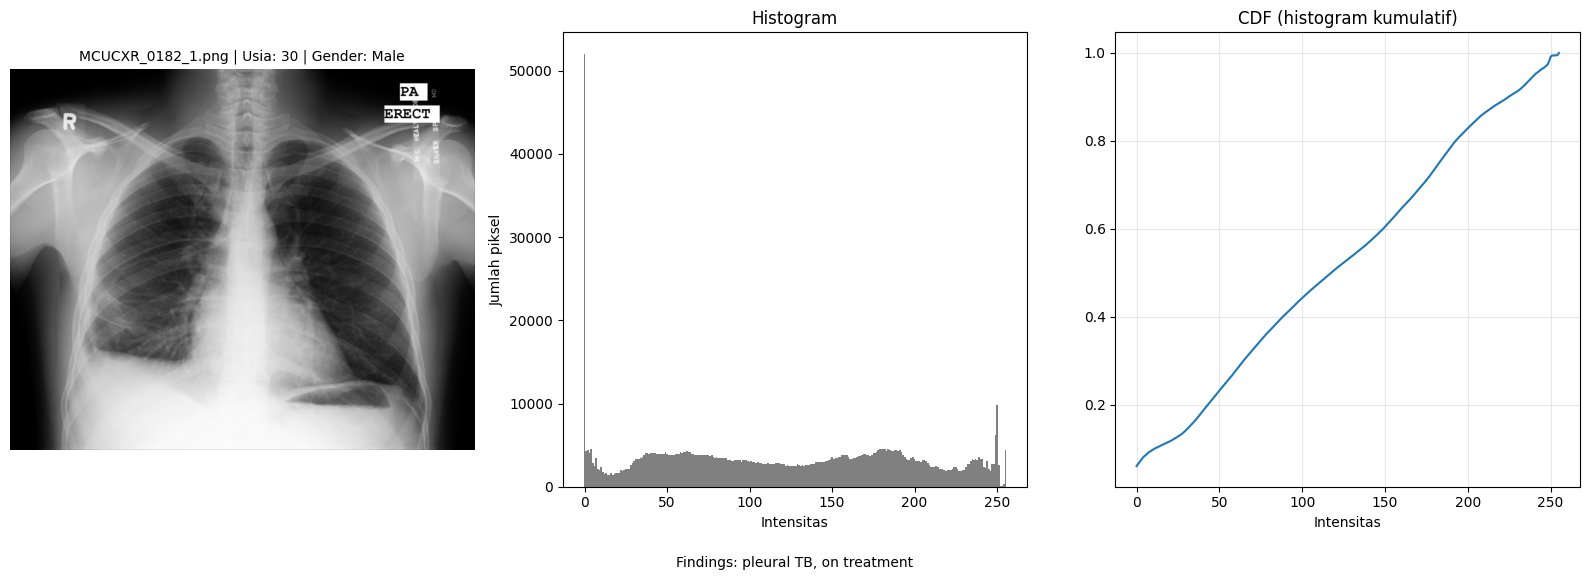

In [3]:
def shannon_entropy(im):
    p = np.bincount(im.ravel(), minlength=256) / im.size
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

# ===================== MEMBACA CITRA =====================
raw = cv2.imread(IMAGE_PATH, cv2.IMREAD_UNCHANGED)
if raw is None:
    raise RuntimeError(f"Gagal membaca {IMAGE_PATH}")

orig_shape, orig_dtype = raw.shape, raw.dtype
if raw.ndim == 3:
    raw = cv2.cvtColor(raw, cv2.COLOR_BGRA2GRAY if raw.shape[2] == 4 else cv2.COLOR_BGR2GRAY)
if raw.dtype != np.uint8:                       # mis. PNG 16-bit -> 8-bit
    raw = cv2.normalize(raw.astype(np.float32), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Sisi terpanjang diperkecil menjadi MAX_SIDE piksel (INTER_AREA) agar eksperimen cepat.
MAX_SIDE = 1024
h0, w0 = raw.shape
scale = MAX_SIDE / max(h0, w0)
img = cv2.resize(raw, (round(w0 * scale), round(h0 * scale)), interpolation=cv2.INTER_AREA) if scale < 1 else raw.copy()
H, W = img.shape

# ===================== METADATA (age, gender, findings) =====================
def _pick_col(cols, patterns):
    for c in cols:
        name = str(c).strip().lower()
        if any(re.search(p, name) for p in patterns):
            return c
    return None

def load_metadata(image_path, search_root="/kaggle/input"):
    stem = os.path.splitext(os.path.basename(image_path))[0]          # MCUCXR_0182_1
    meta, source = {}, None
    roots = [r for r in (search_root, os.path.dirname(image_path), ".") if os.path.isdir(r)]

    # (1) File CSV/XLSX metadata: cari baris yang memuat nama gambar
    for root in roots:
        for dirpath, _, files in os.walk(root):
            for f in files:
                if not f.lower().endswith((".csv", ".xlsx", ".xls")):
                    continue
                fp = os.path.join(dirpath, f)
                try:
                    df = pd.read_excel(fp) if f.lower().endswith((".xlsx", ".xls")) else pd.read_csv(fp)
                except Exception:
                    try:
                        df = pd.read_csv(fp, encoding="latin-1", sep=None, engine="python")
                    except Exception:
                        continue
                hit = df.astype(str).apply(lambda col: col.str.contains(stem, case=False, regex=False)).any(axis=1)
                if not hit.any():
                    continue
                row = df[hit].iloc[0]
                c_age = _pick_col(df.columns, [r"(^|[^a-z])age($|[^a-z])"])
                c_gen = _pick_col(df.columns, [r"gender", r"(^|[^a-z])sex($|[^a-z])"])
                c_fin = _pick_col(df.columns, [r"finding", r"report", r"reading", r"diagnos"])
                meta = {
                    "Age": row[c_age] if c_age is not None else "tidak tersedia",
                    "Gender": row[c_gen] if c_gen is not None else "tidak tersedia",
                    "Findings": row[c_fin] if c_fin is not None else "tidak tersedia",
                }
                return meta, fp

    # (2) Cadangan: file teks klinis per gambar (format asli Montgomery: MCUCXR_0182_1.txt)
    for root in roots:
        for dirpath, _, files in os.walk(root):
            if stem + ".txt" in files:
                fp = os.path.join(dirpath, stem + ".txt")
                txt = open(fp, errors="ignore").read()
                age = re.search(r"age\s*:\s*([^\n\r]+)", txt, re.I)
                sex = re.search(r"sex\s*:\s*([^\n\r]+)", txt, re.I)
                lines = [l.strip() for l in txt.splitlines() if l.strip()
                         and not re.match(r"patient'?s?\s*(sex|age)", l.strip(), re.I)]
                meta = {
                    "Age": age.group(1).strip() if age else "tidak tersedia",
                    "Gender": sex.group(1).strip() if sex else "tidak tersedia",
                    "Findings": " ".join(lines) if lines else "tidak tersedia",
                }
                return meta, fp
    return None, None

metadata, meta_source = load_metadata(IMAGE_PATH)
label = "TB positif / abnormal" if IMAGE_PATH.endswith("_1.png") else "Normal"

# ===================== INFORMASI CITRA =====================
print("=" * 60)
print(f"Nama file            : {os.path.basename(IMAGE_PATH)}  (label dataset: {label})")
print(f"Lokasi               : {IMAGE_PATH}")
print(f"Ukuran file          : {os.path.getsize(IMAGE_PATH)/1024:.1f} KB")
print(f"Dimensi asli (shape) : {orig_shape}  dtype={orig_dtype}")
print(f"Dimensi untuk proses : {img.shape}  dtype={img.dtype}  (skala {scale:.3f})")
print(f"Intensitas min / max : {img.min()} / {img.max()}")
print(f"Mean / Median / Std  : {img.mean():.2f} / {np.median(img):.1f} / {img.std():.2f}")
print(f"Persentil 1% / 99%   : {np.percentile(img,1):.0f} / {np.percentile(img,99):.0f}")
print(f"Jumlah level abu-abu : {len(np.unique(img))}")
print(f"Entropi Shannon      : {shannon_entropy(img):.4f} bit")
print("-" * 60)
if metadata:
    print(f"METADATA PASIEN (sumber: {meta_source})")
    for k, v in metadata.items():
        print(f"  {k:<8}: {v}")
else:
    print("METADATA PASIEN: tidak ditemukan pada /kaggle/input "
          "(pastikan dataset yang memuat file metadata ikut di-attach via 'Add Input').")
print("=" * 60)

# ===================== VISUALISASI =====================
if metadata:
    title = (f"{os.path.basename(IMAGE_PATH)} | Usia: {metadata['Age']} | "
             f"Gender: {metadata['Gender']}")
else:
    title = f"{os.path.basename(IMAGE_PATH)} | {label}"

hist = np.bincount(img.ravel(), minlength=256)
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
ax[0].imshow(img, cmap="gray", vmin=0, vmax=255); ax[0].set_title(title, fontsize=10); ax[0].axis("off")
ax[1].bar(range(256), hist, width=1.0, color="gray"); ax[1].set_title("Histogram"); ax[1].set_xlabel("Intensitas"); ax[1].set_ylabel("Jumlah piksel")
ax[2].plot(np.cumsum(hist) / hist.sum()); ax[2].set_title("CDF (histogram kumulatif)"); ax[2].set_xlabel("Intensitas"); ax[2].grid(True, alpha=.3)
if metadata and str(metadata["Findings"]) != "tidak tersedia":
    import textwrap
    fig.text(0.5, -0.02, "Findings: " + textwrap.fill(str(metadata["Findings"]), 150), ha="center", va="top", fontsize=10)
plt.tight_layout(); plt.show()

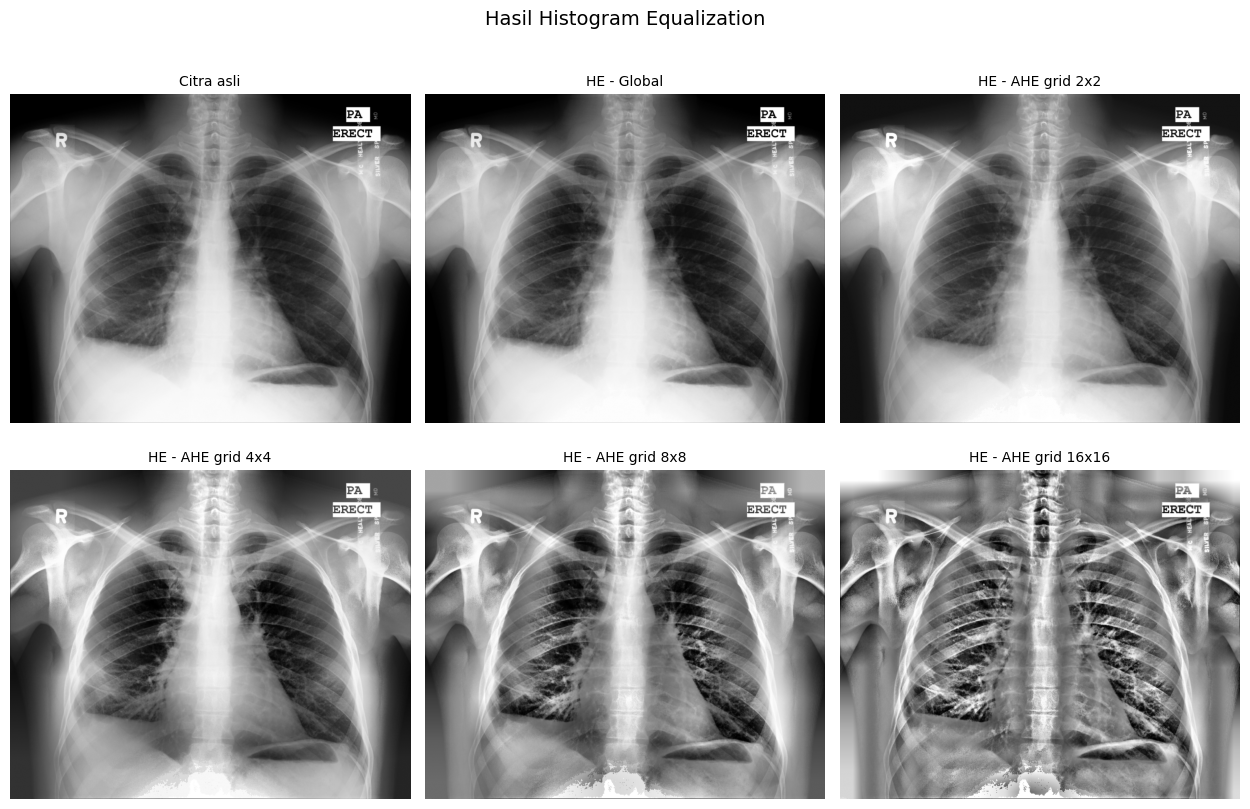

Perbandingan kuantitatif HE (baseline citra asli: Entropy=7.778, Kontras (Std)=75.536, EME=20.370, Sharpness (VarLap)=131.828, AMBE=0.000)


,Parameter,Entropy,Kontras (Std),EME,Sharpness (VarLap),AMBE,PSNR (dB),SSIM
0,Global,7.6441,77.6195,21.1667,139.6166,0.9343,36.1806,0.9908
1,AHE grid 2x2,7.8022,71.5902,13.4173,148.0102,8.8072,23.5476,0.8996
2,AHE grid 4x4,7.8657,64.9094,17.3199,222.9164,10.8207,15.6525,0.7954
3,AHE grid 8x8,7.7130,54.3834,21.8927,430.7282,14.2585,12.3327,0.6621
4,AHE grid 16x16,7.5494,49.1586,28.4560,950.4775,17.8202,10.2858,0.4960


In [4]:
# ===================== FUNGSI BANTU (dipakai oleh seluruh metode peningkatan) =====================
def eme(im, k=8):
    # Measure of Enhancement: rata-rata 20*log10(Imax/Imin) pada blok k x k
    h, w = im.shape
    bh, bw = h // k, w // k
    blk = im[:bh * k, :bw * k].astype(np.float64).reshape(k, bh, k, bw)
    mx, mn = blk.max(axis=(1, 3)), blk.min(axis=(1, 3))
    return float(np.mean(20 * np.log10((mx + 1) / (mn + 1))))

METRICS = ["Entropy", "Kontras (Std)", "EME", "Sharpness (VarLap)", "AMBE", "PSNR (dB)", "SSIM"]

def evaluate(enh, ref=None):
    ref = img if ref is None else ref
    return {
        "Entropy": shannon_entropy(enh),                                  # kaya informasi (lebih besar lebih baik)
        "Kontras (Std)": float(enh.std()),                                # kontras global (lebih besar lebih baik)
        "EME": eme(enh),                                                  # kontras lokal (lebih besar lebih baik)
        "Sharpness (VarLap)": float(cv2.Laplacian(enh, cv2.CV_64F).var()),# ketajaman / detail (juga naik jika noise naik)
        "AMBE": abs(float(enh.mean()) - float(ref.mean())),               # pergeseran brightness (lebih kecil lebih baik)
        "PSNR (dB)": float(psnr(ref, enh, data_range=255)),               # kemiripan thd asli
        "SSIM": float(ssim(ref, enh, data_range=255)),                    # kemiripan struktur thd asli
    }

BASELINE = {k: v for k, v in evaluate(img).items() if k not in ("PSNR (dB)", "SSIM")}
BASELINE["AMBE"] = 0.0

ALL_ROWS, IMAGES = [], {}
def register(method, param, enh, **extra):
    row = {"Metode": method, "Parameter": param, **evaluate(enh), **extra}
    ALL_ROWS.append(row)
    IMAGES[(method, param)] = enh
    return row

def show_grid(items, ncols=4, size=4.2, title=None):
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, (t, im) in zip(axes, items):
        if im.ndim == 3: ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else: ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=10)
    if title: fig.suptitle(title, fontsize=14, y=1.0)
    plt.tight_layout(); plt.show()

def bar_metrics(df, title):
    fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    axes = axes.ravel()
    for ax, m in zip(axes, METRICS):
        ax.bar(range(len(df)), df[m], color=plt.cm.viridis(np.linspace(.15, .85, len(df))))
        if m in BASELINE: ax.axhline(BASELINE[m], color="red", ls="--", lw=1.2, label="Citra asli")
        ax.set_xticks(range(len(df))); ax.set_xticklabels(df["Parameter"], rotation=60, ha="right", fontsize=8)
        ax.set_title(m + (" (lebih kecil lebih baik)" if m == "AMBE" else "")); ax.grid(axis="y", alpha=.3)
        if m in BASELINE: ax.legend(fontsize=8)
    axes[-1].axis("off")
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

# ===================== HISTOGRAM EQUALIZATION =====================
# HE global tidak punya parameter. Agar variasi grid size dapat diuji, keluarga HE di sini terdiri dari:
#   - Global HE
#   - AHE (Adaptive HE = HE per tile, TANPA pembatasan kontras / clip limit tidak aktif)
# Eksperimen clip limit x grid size yang sesungguhnya dilakukan pada CLAHE (sel berikutnya).
he_variants = [("Global", cv2.equalizeHist(img))]
for g in [(2, 2), (4, 4), (8, 8), (16, 16)]:
    ahe = cv2.createCLAHE(clipLimit=1000.0, tileGridSize=g).apply(img)    # clip sangat besar = tanpa clip
    he_variants.append((f"AHE grid {g[0]}x{g[1]}", ahe))

rows, items = [], [("Citra asli", img)]
for name, enh in he_variants:
    rows.append(register("HE", name, enh))
    items.append((f"HE - {name}", enh))
show_grid(items, ncols=3, title="Hasil Histogram Equalization")

df_he = pd.DataFrame(rows)
print("Perbandingan kuantitatif HE (baseline citra asli: " +
      ", ".join(f"{k}={v:.3f}" for k, v in BASELINE.items()) + ")")
display(df_he.drop(columns="Metode").round(4))

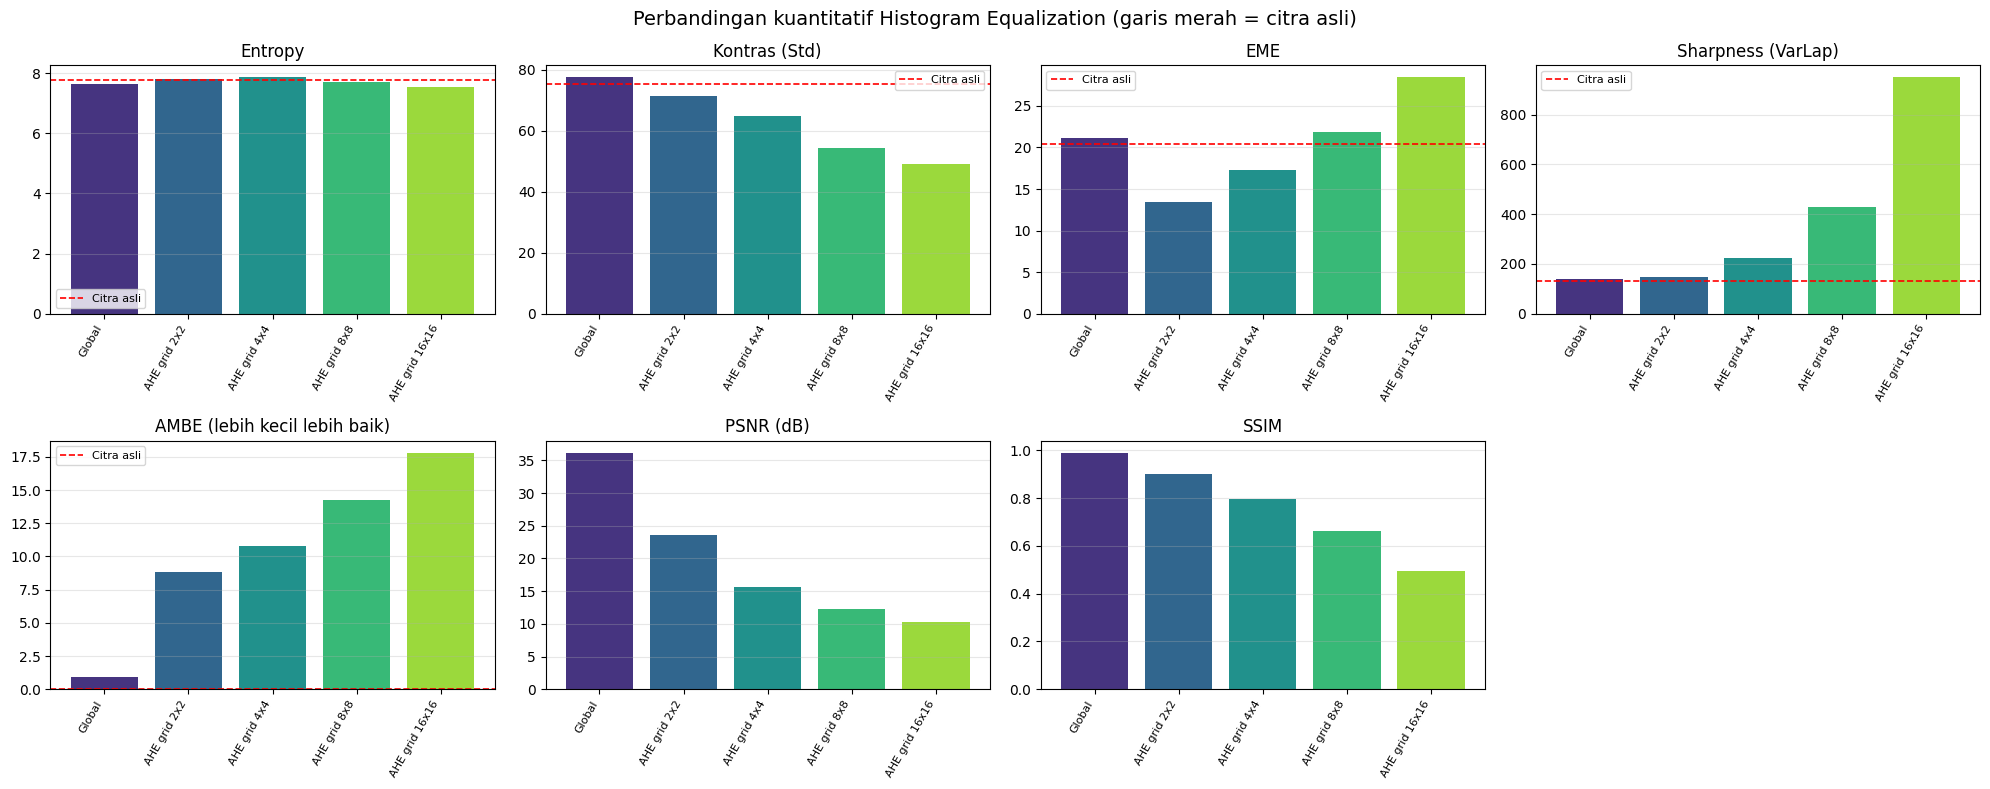

In [5]:
bar_metrics(df_he, "Perbandingan kuantitatif Histogram Equalization (garis merah = citra asli)")

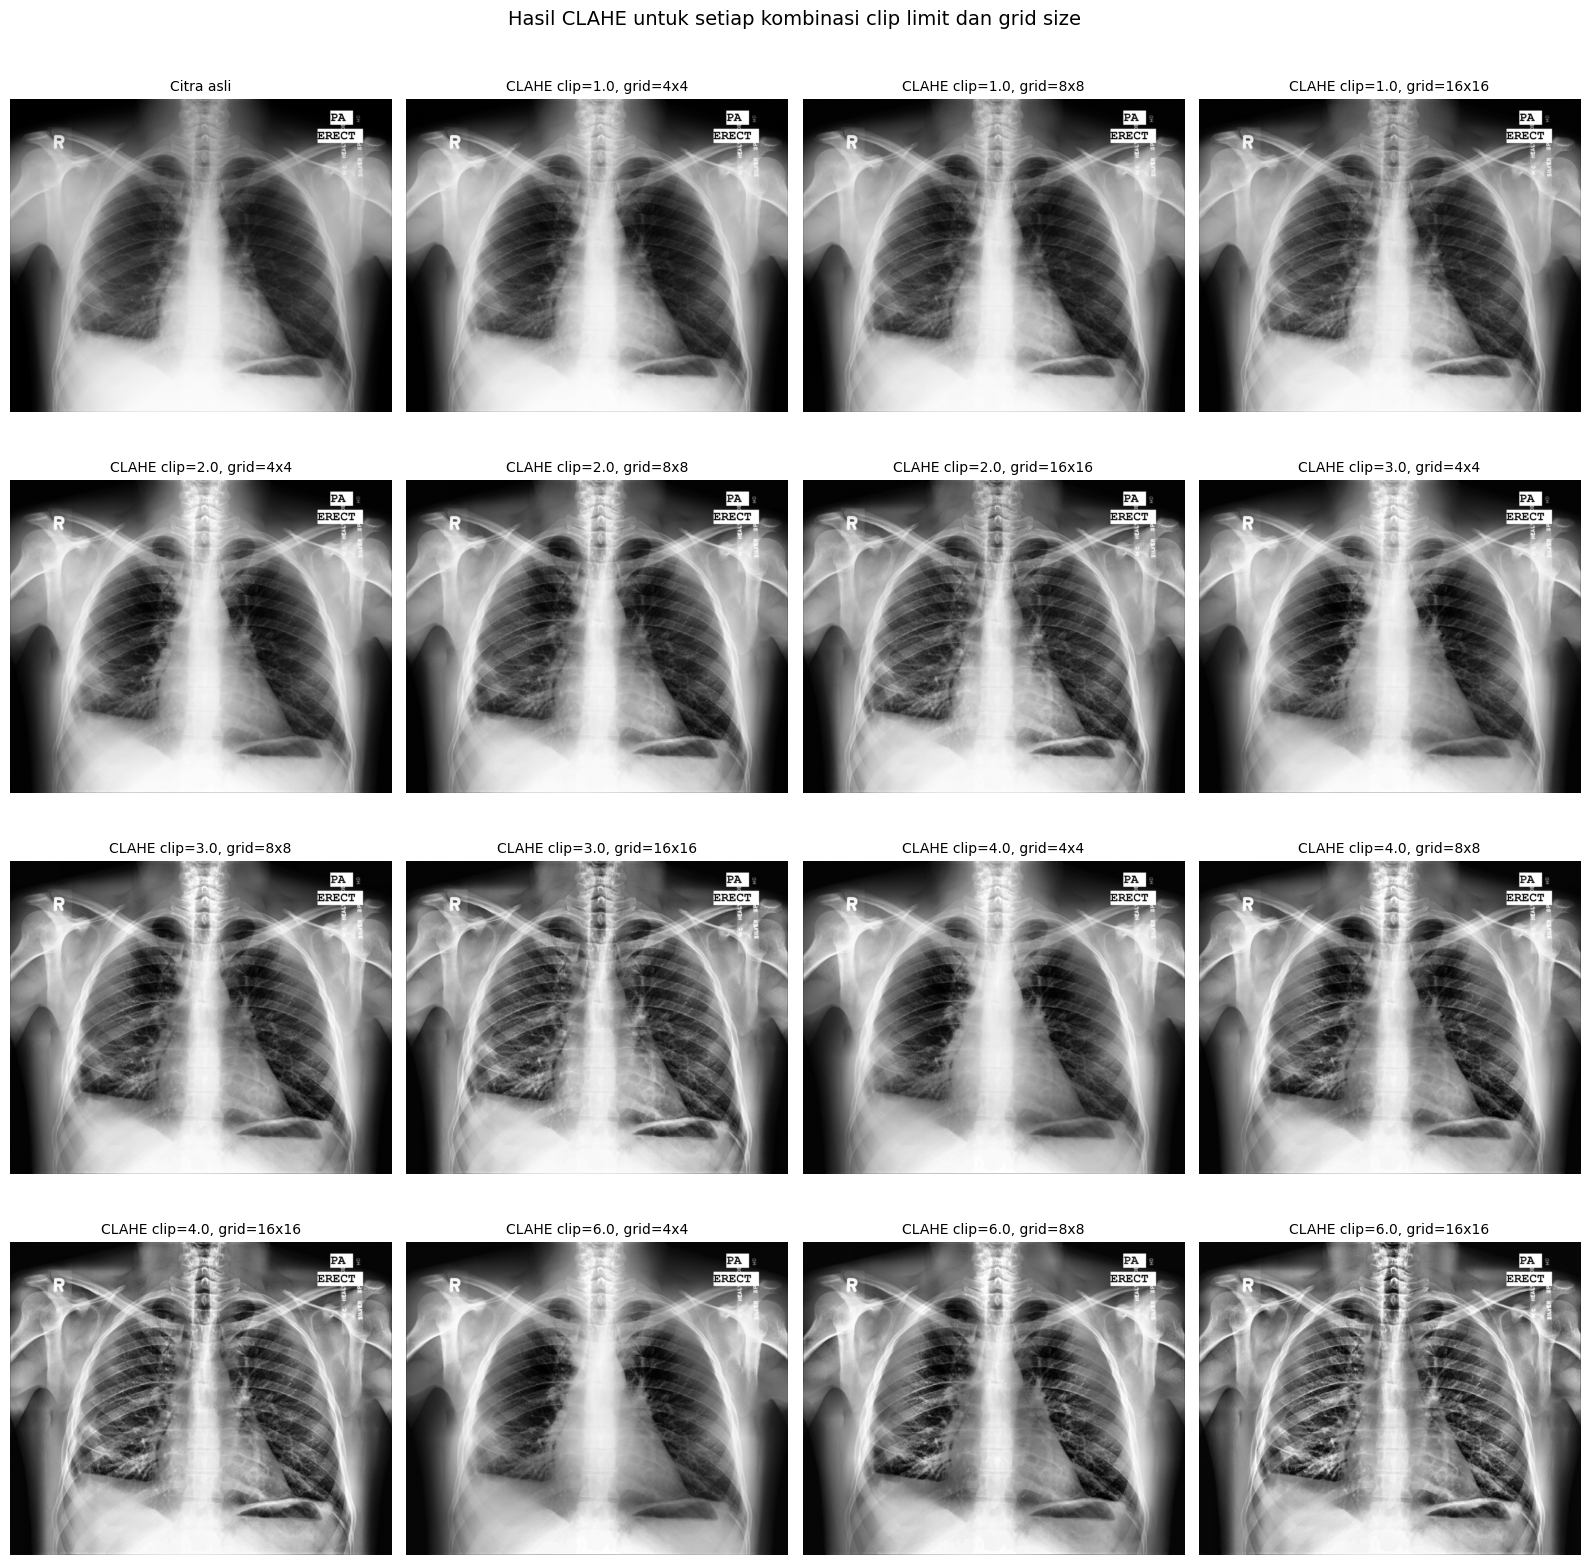

Perbandingan kuantitatif CLAHE


,Parameter,Entropy,Kontras (Std),EME,Sharpness (VarLap),AMBE,PSNR (dB),SSIM
0,clip 1.0 | grid 4x4,7.7950,77.7586,20.7315,165.6991,5.9055,25.0901,0.9712
1,clip 1.0 | grid 8x8,7.8310,75.5096,20.8594,163.0258,4.2501,26.5520,0.9507
2,clip 1.0 | grid 16x16,7.7775,73.2280,19.5017,168.2261,3.8542,27.9564,0.9372
3,clip 2.0 | grid 4x4,7.7990,76.8256,21.1382,195.6799,8.1525,20.7374,0.9190
4,clip 2.0 | grid 8x8,7.8442,73.8571,22.4046,202.0209,5.8987,21.4250,0.8841
5,clip 2.0 | grid 16x16,7.7889,71.0936,20.5489,216.2247,6.1842,22.7319,0.8578
6,clip 3.0 | grid 4x4,7.7877,75.3858,21.3344,212.2032,8.6157,19.3118,0.8819
7,clip 3.0 | grid 8x8,7.8293,71.7182,23.3583,235.4138,6.6753,18.9541,0.8242
8,clip 3.0 | grid 16x16,7.7745,68.8361,21.8302,273.3900,7.5954,19.8073,0.7772
9,clip 4.0 | grid 4x4,7.7813,74.3859,21.0661,223.8405,7.8523,18.6337,0.8613


In [6]:
# ===================== CLAHE: kombinasi clip limit x grid size =====================
clip_limits = [1.0, 2.0, 3.0, 4.0, 6.0]
grid_sizes = [(4, 4), (8, 8), (16, 16)]

rows, items = [], [("Citra asli", img)]
for c in clip_limits:
    for g in grid_sizes:
        enh = cv2.createCLAHE(clipLimit=c, tileGridSize=g).apply(img)
        rows.append(register("CLAHE", f"clip {c} | grid {g[0]}x{g[1]}", enh, Clip=c, Grid=g[0]))
        items.append((f"CLAHE clip={c}, grid={g[0]}x{g[1]}", enh))
show_grid(items, ncols=4, size=4, title="Hasil CLAHE untuk setiap kombinasi clip limit dan grid size")

df_clahe = pd.DataFrame(rows)
print("Perbandingan kuantitatif CLAHE")
display(df_clahe.drop(columns=["Metode", "Clip", "Grid"]).round(4))

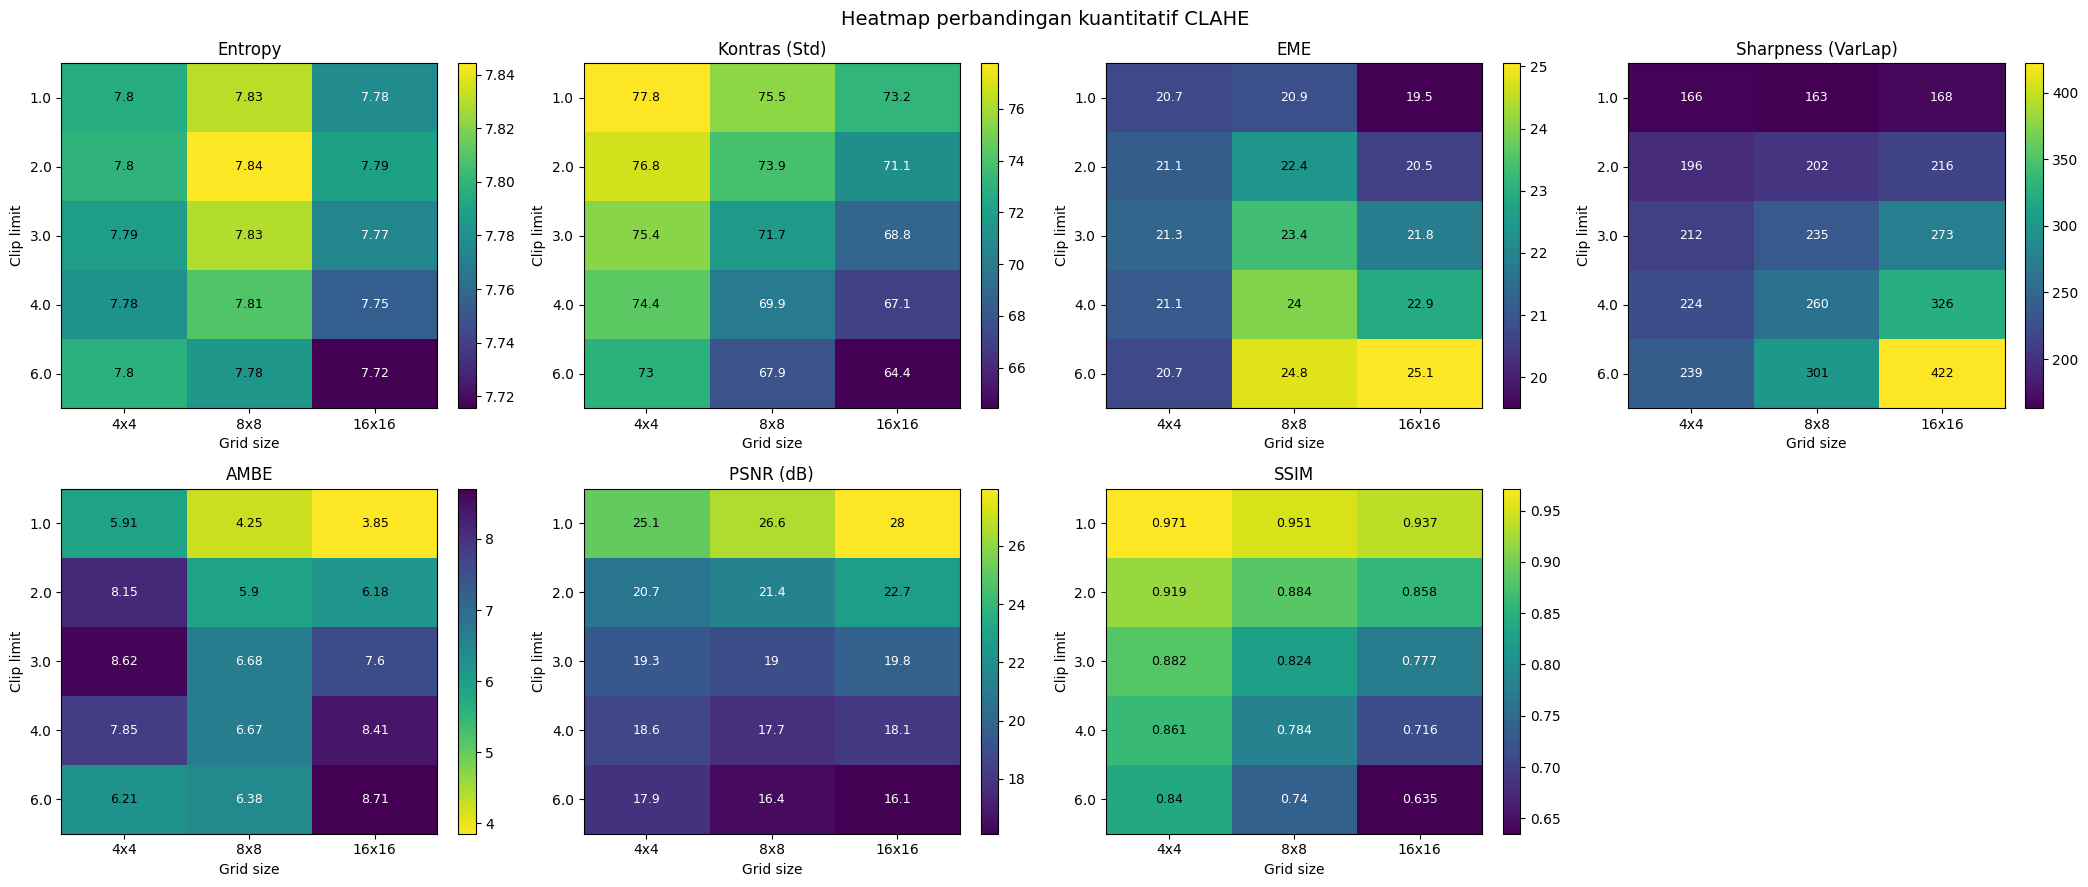

In [7]:
# Heatmap metrik untuk setiap kombinasi clip limit (baris) x grid size (kolom)
fig, axes = plt.subplots(2, 4, figsize=(21, 9))
axes = axes.ravel()
for ax, m in zip(axes, METRICS):
    pv = df_clahe.pivot(index="Clip", columns="Grid", values=m)
    cmap = "viridis_r" if m == "AMBE" else "viridis"      # AMBE: kecil = baik
    im_ = ax.imshow(pv.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels([f"{c}x{c}" for c in pv.columns])
    ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index)
    ax.set_xlabel("Grid size"); ax.set_ylabel("Clip limit"); ax.set_title(m)
    vmin, vmax = pv.values.min(), pv.values.max()
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.values[i, j]
            dark = (v - vmin) / (vmax - vmin + 1e-12) < .5
            if m == "AMBE": dark = not dark
            ax.text(j, i, f"{v:.3g}", ha="center", va="center", fontsize=9, color="white" if dark else "black")
    plt.colorbar(im_, ax=ax, fraction=.046)
axes[-1].axis("off")
fig.suptitle("Heatmap perbandingan kuantitatif CLAHE", fontsize=14); plt.tight_layout(); plt.show()

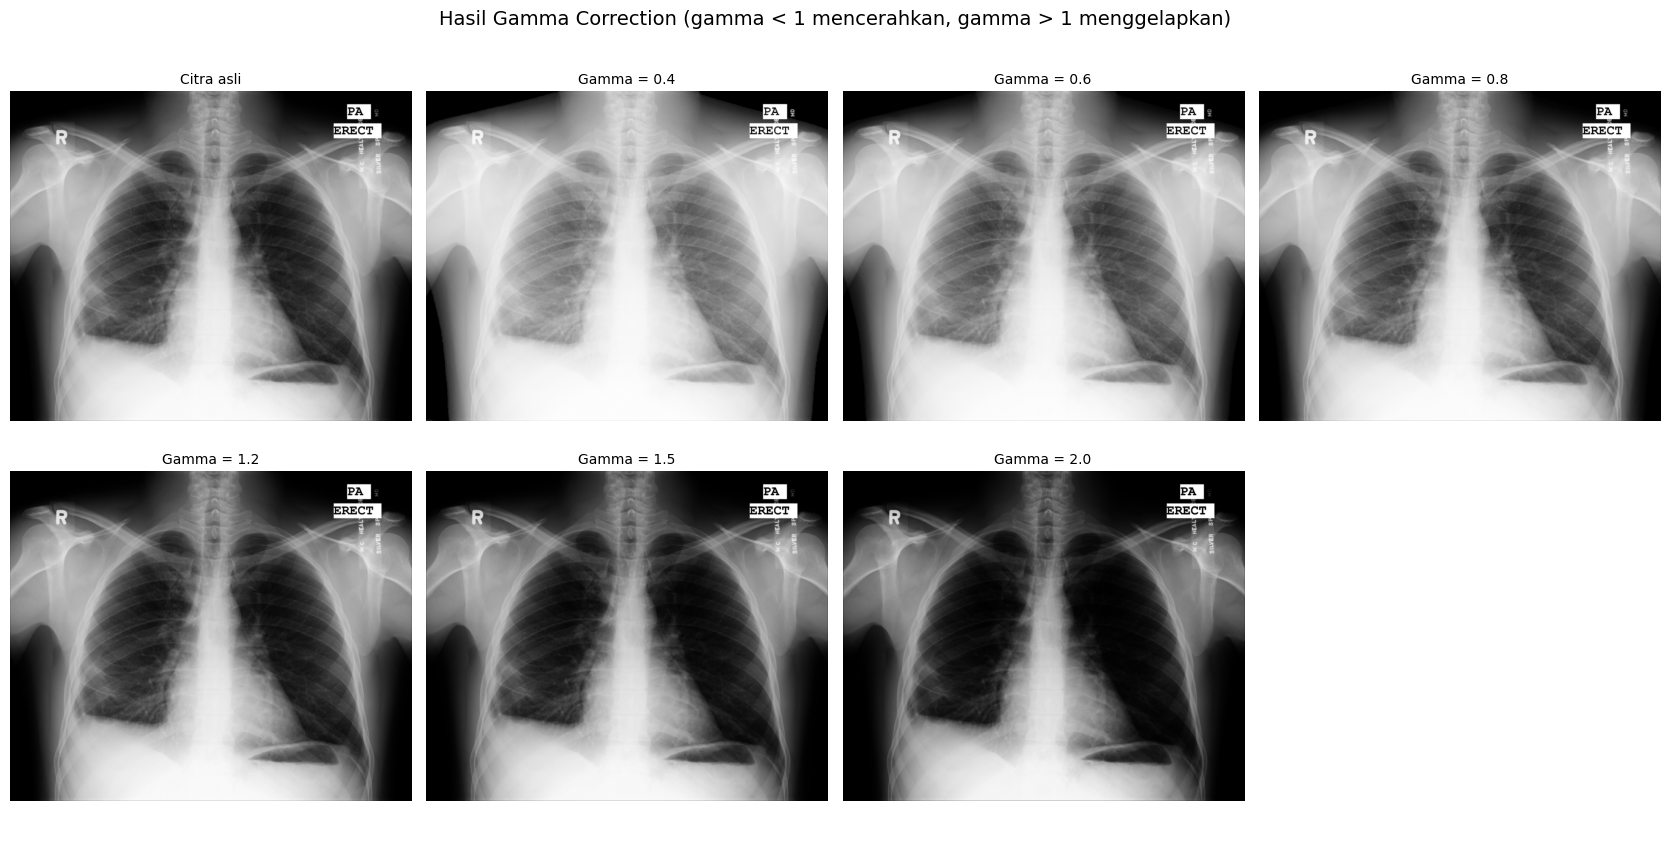

Perbandingan kuantitatif Gamma Correction


,Parameter,Entropy,Kontras (Std),EME,Sharpness (VarLap),AMBE,PSNR (dB),SSIM
0,gamma 0.4,7.1572,66.6609,14.9916,101.6767,52.3287,12.7025,0.8116
1,gamma 0.6,7.4520,71.2271,16.8286,110.2636,30.6237,17.4214,0.8975
2,gamma 0.8,7.6360,74.0121,18.6316,121.4882,13.6803,24.4479,0.9691
3,gamma 1.2,7.6412,76.1662,22.0533,143.9308,11.2222,26.1990,0.9720
4,gamma 1.5,7.4388,76.0613,24.3372,161.0293,24.6951,19.3439,0.8771
5,gamma 2.0,7.0886,74.3378,27.6568,186.9173,41.1309,14.8880,0.7146


In [8]:
# ===================== GAMMA CORRECTION: s = 255 * (r/255)^gamma =====================
gammas = [0.4, 0.6, 0.8, 1.2, 1.5, 2.0]

rows, items = [], [("Citra asli", img)]
for gm in gammas:
    lut = np.array([255.0 * (i / 255.0) ** gm for i in range(256)]).round().clip(0, 255).astype(np.uint8)
    enh = cv2.LUT(img, lut)
    rows.append(register("Gamma", f"gamma {gm}", enh, Gamma=gm))
    items.append((f"Gamma = {gm}", enh))
show_grid(items, ncols=4, title="Hasil Gamma Correction (gamma < 1 mencerahkan, gamma > 1 menggelapkan)")

df_gamma = pd.DataFrame(rows)
print("Perbandingan kuantitatif Gamma Correction")
display(df_gamma.drop(columns=["Metode", "Gamma"]).round(4))

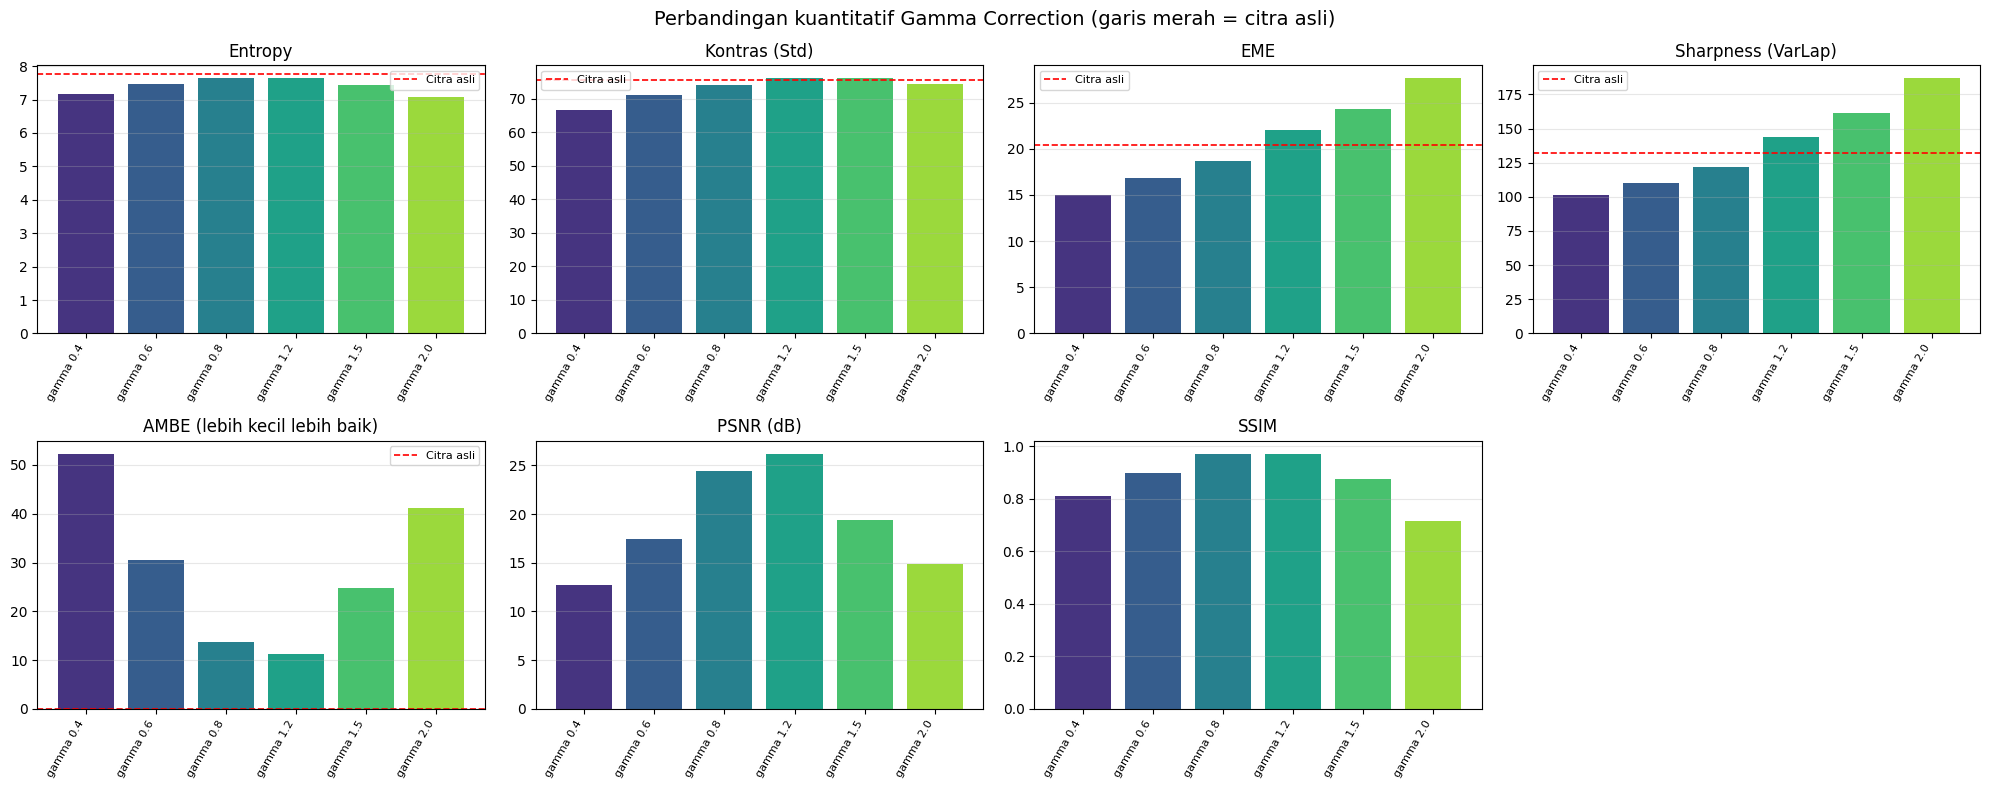

In [9]:
bar_metrics(df_gamma, "Perbandingan kuantitatif Gamma Correction (garis merah = citra asli)")

TOP 8 kandidat berdasarkan skor gabungan


,Metode,Parameter,Entropy,Kontras (Std),EME,Sharpness (VarLap),AMBE,PSNR (dB),SSIM,Skor
0,CLAHE,clip 1.0 | grid 4x4,7.7950,77.7586,20.7315,165.6991,5.9055,25.0901,0.9712,0.8518
1,CLAHE,clip 1.0 | grid 8x8,7.8310,75.5096,20.8594,163.0258,4.2501,26.5520,0.9507,0.8452
2,HE,Global,7.6441,77.6195,21.1667,139.6166,0.9343,36.1806,0.9908,0.8450
3,CLAHE,clip 2.0 | grid 8x8,7.8442,73.8571,22.4046,202.0209,5.8987,21.4250,0.8841,0.8242
4,CLAHE,clip 2.0 | grid 4x4,7.7990,76.8256,21.1382,195.6799,8.1525,20.7374,0.9190,0.8219
5,Gamma,gamma 1.2,7.6412,76.1662,22.0533,143.9308,11.2222,26.1990,0.9720,0.7983
6,CLAHE,clip 3.0 | grid 4x4,7.7877,75.3858,21.3344,212.2032,8.6157,19.3118,0.8819,0.7947
7,CLAHE,clip 1.0 | grid 16x16,7.7775,73.2280,19.5017,168.2261,3.8542,27.9564,0.9372,0.7935


Parameter terbaik untuk tiap metode


,Metode,Parameter,Entropy,Kontras (Std),EME,Sharpness (VarLap),AMBE,PSNR (dB),SSIM,Skor
0,CLAHE,clip 1.0 | grid 4x4,7.7950,77.7586,20.7315,165.6991,5.9055,25.0901,0.9712,0.8518
1,HE,Global,7.6441,77.6195,21.1667,139.6166,0.9343,36.1806,0.9908,0.8450
2,Gamma,gamma 1.2,7.6412,76.1662,22.0533,143.9308,11.2222,26.1990,0.9720,0.7983


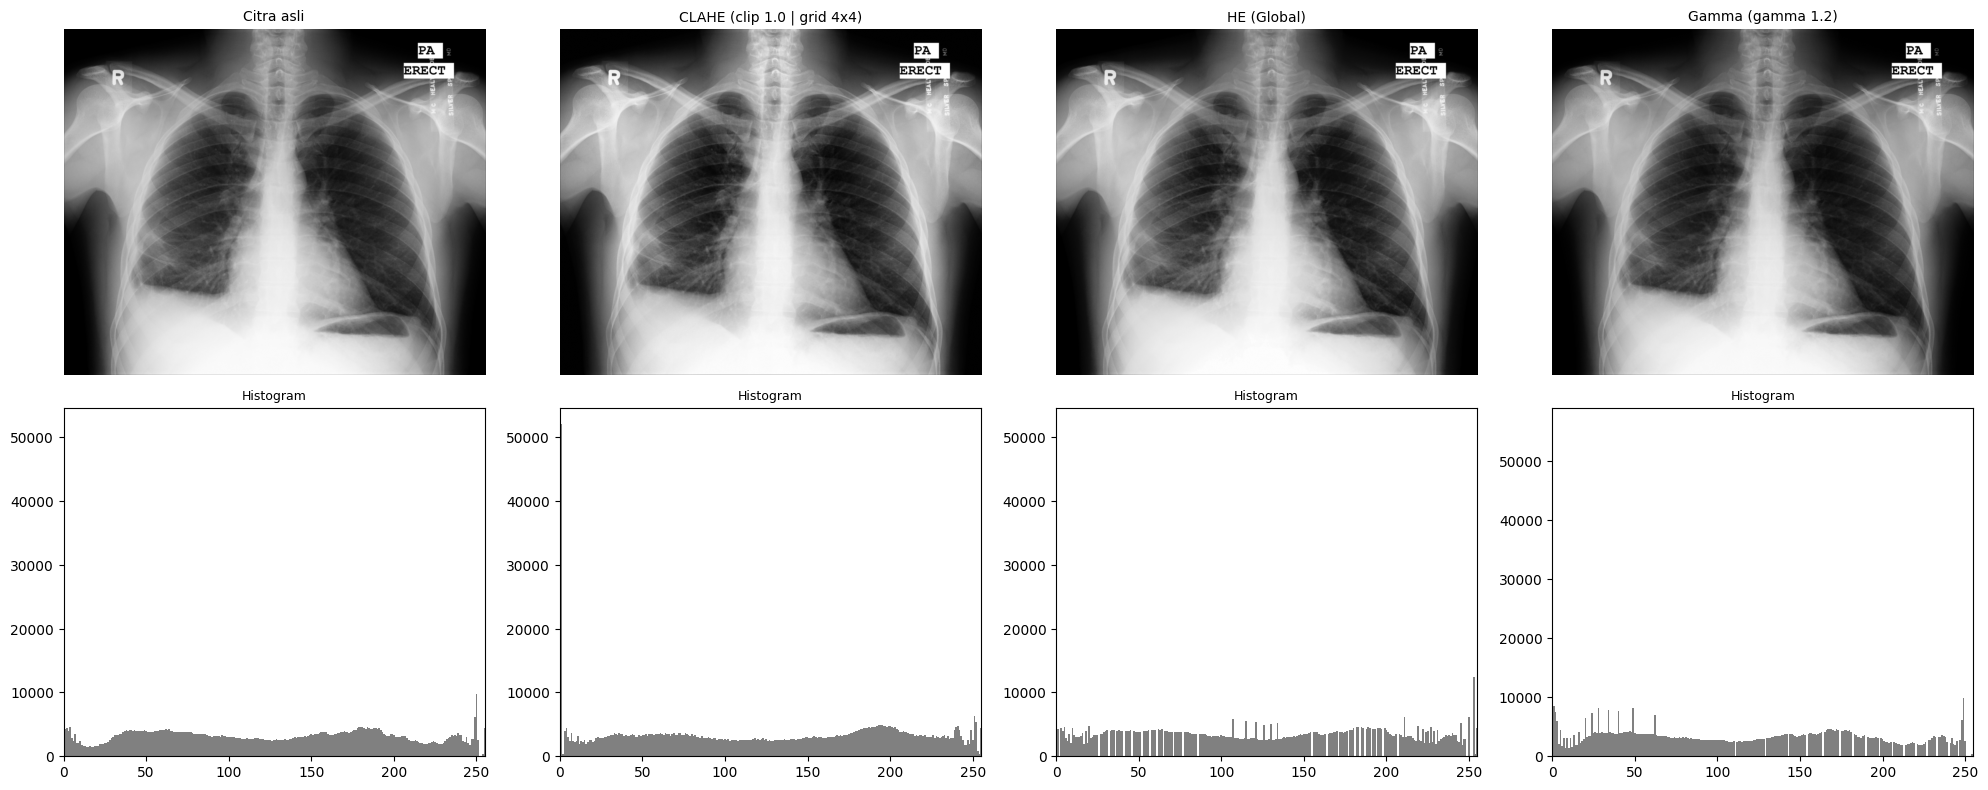

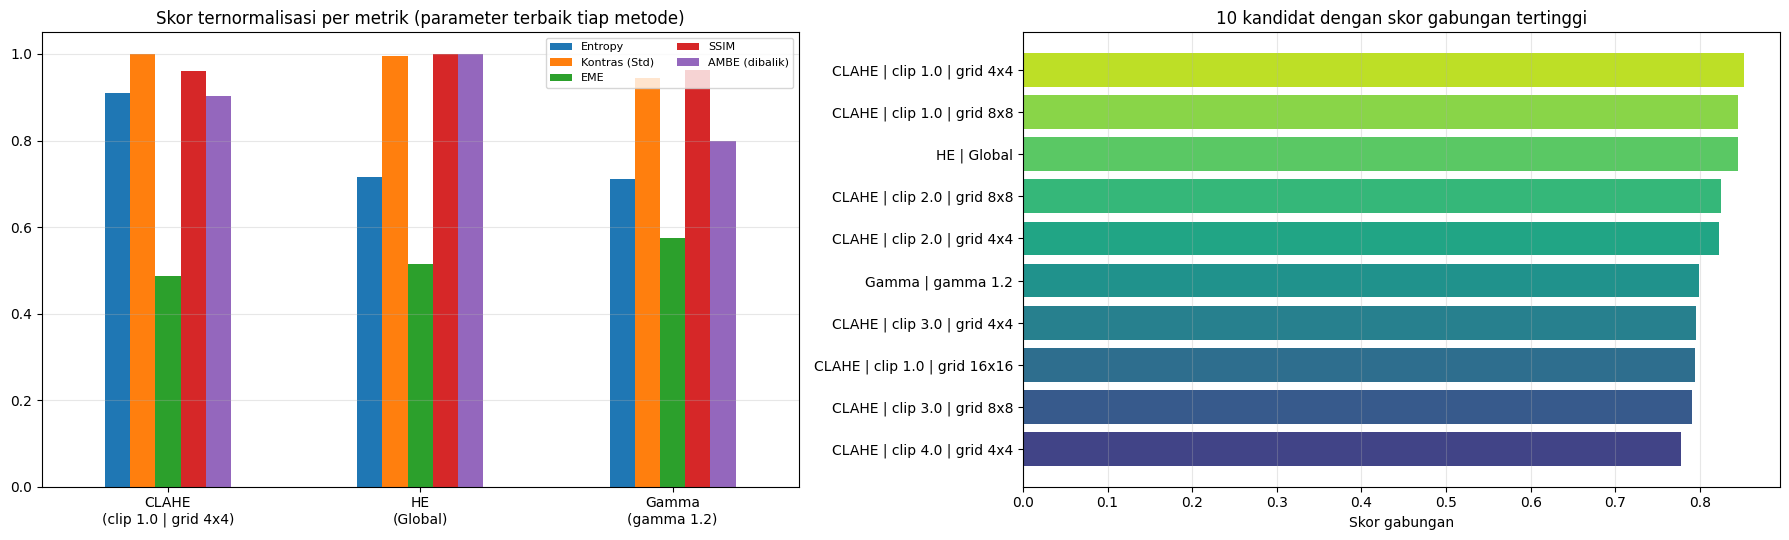

>>> Metode peningkatan terbaik: CLAHE (clip 1.0 | grid 4x4) | skor = 0.8518
>>> Citra ini dipakai sebagai masukan untuk tahap segmentasi.


In [10]:
# ===================== PERBANDINGAN ANTAR METODE =====================
# Skor gabungan = rata-rata 5 metrik yang dinormalisasi min-max pada SELURUH kandidat (bobot sama):
#   naik lebih baik  : Entropy, Kontras (Std), EME, SSIM (struktur anatomi tetap terjaga)
#   turun lebih baik : AMBE (brightness tidak bergeser jauh)
# Sharpness dan PSNR tetap dilaporkan tetapi tidak masuk skor (sharpness ikut naik saat noise naik).
df_all = pd.DataFrame(ALL_ROWS)
def minmax(s): return (s - s.min()) / (s.max() - s.min() + 1e-12)
NORM = pd.DataFrame({m: minmax(df_all[m]) for m in ["Entropy", "Kontras (Std)", "EME", "SSIM"]})
NORM["AMBE (dibalik)"] = 1 - minmax(df_all["AMBE"])
df_all["Skor"] = NORM.mean(axis=1)

cols = ["Metode", "Parameter"] + METRICS + ["Skor"]
print("TOP 8 kandidat berdasarkan skor gabungan")
display(df_all.sort_values("Skor", ascending=False)[cols].head(8).round(4).reset_index(drop=True))

best_idx = df_all.groupby("Metode")["Skor"].idxmax()
best_per_method = df_all.loc[best_idx].sort_values("Skor", ascending=False).reset_index(drop=True)
print("Parameter terbaik untuk tiap metode")
display(best_per_method[cols].round(4))

# --- visual: citra + histogram parameter terbaik tiap metode
show = [("Citra asli", img)] + [(f"{r.Metode} ({r.Parameter})", IMAGES[(r.Metode, r.Parameter)]) for r in best_per_method.itertuples()]
fig, axes = plt.subplots(2, len(show), figsize=(5 * len(show), 8))
for j, (t, im_) in enumerate(show):
    axes[0, j].imshow(im_, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(t, fontsize=10); axes[0, j].axis("off")
    axes[1, j].bar(range(256), np.bincount(im_.ravel(), minlength=256), width=1.0, color="gray")
    axes[1, j].set_title("Histogram", fontsize=9); axes[1, j].set_xlim(0, 255)
plt.tight_layout(); plt.show()

# --- visual: skor per metrik (ternormalisasi) dan peringkat skor gabungan
fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
nm = NORM.loc[best_idx[best_per_method["Metode"]].values]
nm.index = best_per_method["Metode"] + "\n(" + best_per_method["Parameter"] + ")"
nm.plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("Skor ternormalisasi per metrik (parameter terbaik tiap metode)")
ax[0].set_ylim(0, 1.05); ax[0].legend(fontsize=8, ncol=2); ax[0].grid(axis="y", alpha=.3)
top = df_all.sort_values("Skor", ascending=False).head(10).iloc[::-1]
ax[1].barh(top["Metode"] + " | " + top["Parameter"], top["Skor"], color=plt.cm.viridis(np.linspace(.2, .9, len(top))))
ax[1].set_title("10 kandidat dengan skor gabungan tertinggi"); ax[1].set_xlabel("Skor gabungan"); ax[1].grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

best_row = df_all.loc[df_all["Skor"].idxmax()]
BEST_KEY = (best_row["Metode"], best_row["Parameter"])
best_img = IMAGES[BEST_KEY]
print(f">>> Metode peningkatan terbaik: {BEST_KEY[0]} ({BEST_KEY[1]}) | skor = {best_row['Skor']:.4f}")
print(">>> Citra ini dipakai sebagai masukan untuk tahap segmentasi.")

In [11]:
# Analisis kuantitatif ditulis otomatis sebagai Markdown dari angka hasil eksekusi (supaya selalu konsisten).
b = best_row
L = []
L.append("## Analisis Hasil Peningkatan Citra\n")
L.append(f"**Metode terbaik berdasarkan skor gabungan: {b['Metode']} ({b['Parameter']})** dengan skor **{b['Skor']:.3f}**.\n")

L.append("| Metode | Parameter terbaik | Skor | Entropy | Kontras | EME | SSIM | AMBE |")
L.append("|---|---|---|---|---|---|---|---|")
L.append(f"| Citra asli | - | - | {BASELINE['Entropy']:.3f} | {BASELINE['Kontras (Std)']:.2f} | {BASELINE['EME']:.3f} | 1.000 | 0.00 |")
for _, r in best_per_method.iterrows():
    L.append(f"| {r['Metode']} | {r['Parameter']} | {r['Skor']:.3f} | {r['Entropy']:.3f} | {r['Kontras (Std)']:.2f} | {r['EME']:.3f} | {r['SSIM']:.3f} | {r['AMBE']:.2f} |")

L.append("\n**Perubahan metode terbaik terhadap citra asli**\n")
L.append(f"- Entropy: {BASELINE['Entropy']:.3f} -> {b['Entropy']:.3f} ({b['Entropy']-BASELINE['Entropy']:+.3f} bit)")
L.append(f"- Kontras (Std): {BASELINE['Kontras (Std)']:.2f} -> {b['Kontras (Std)']:.2f} ({(b['Kontras (Std)']/BASELINE['Kontras (Std)']-1)*100:+.1f}%)")
L.append(f"- EME (kontras lokal): {BASELINE['EME']:.3f} -> {b['EME']:.3f} ({(b['EME']/BASELINE['EME']-1)*100:+.1f}%)")
L.append(f"- SSIM terhadap asli: {b['SSIM']:.3f}; PSNR: {b['PSNR (dB)']:.2f} dB; AMBE: {b['AMBE']:.2f}")

L.append("\n**Pemenang per metrik (seluruh kandidat)** - menunjukkan adanya trade-off antar metrik:\n")
for m, hi in [("Entropy", True), ("Kontras (Std)", True), ("EME", True), ("Sharpness (VarLap)", True), ("SSIM", True), ("AMBE", False)]:
    r = df_all.loc[df_all[m].idxmax() if hi else df_all[m].idxmin()]
    L.append(f"- {m}: **{r['Metode']} ({r['Parameter']})** = {r[m]:.3f}")

mean_by_method = df_all.groupby("Metode")[["Entropy", "Kontras (Std)", "EME", "SSIM", "AMBE", "Skor"]].mean().round(3)
L.append("\n**Rata-rata seluruh parameter per metode** (menggambarkan kestabilan metode terhadap pemilihan parameter):\n")
L.append("| Metode | Entropy | Kontras | EME | SSIM | AMBE | Skor |")
L.append("|---|---|---|---|---|---|---|")
for name, r in mean_by_method.iterrows():
    L.append(f"| {name} | {r['Entropy']:.3f} | {r['Kontras (Std)']:.2f} | {r['EME']:.3f} | {r['SSIM']:.3f} | {r['AMBE']:.2f} | {r['Skor']:.3f} |")
display(Markdown("\n".join(L)))

## Analisis Hasil Peningkatan Citra

**Metode terbaik berdasarkan skor gabungan: CLAHE (clip 1.0 | grid 4x4)** dengan skor **0.852**.

| Metode | Parameter terbaik | Skor | Entropy | Kontras | EME | SSIM | AMBE |
|---|---|---|---|---|---|---|---|
| Citra asli | - | - | 7.778 | 75.54 | 20.370 | 1.000 | 0.00 |
| CLAHE | clip 1.0 | grid 4x4 | 0.852 | 7.795 | 77.76 | 20.732 | 0.971 | 5.91 |
| HE | Global | 0.845 | 7.644 | 77.62 | 21.167 | 0.991 | 0.93 |
| Gamma | gamma 1.2 | 0.798 | 7.641 | 76.17 | 22.053 | 0.972 | 11.22 |

**Perubahan metode terbaik terhadap citra asli**

- Entropy: 7.778 -> 7.795 (+0.017 bit)
- Kontras (Std): 75.54 -> 77.76 (+2.9%)
- EME (kontras lokal): 20.370 -> 20.732 (+1.8%)
- SSIM terhadap asli: 0.971; PSNR: 25.09 dB; AMBE: 5.91

**Pemenang per metrik (seluruh kandidat)** - menunjukkan adanya trade-off antar metrik:

- Entropy: **HE (AHE grid 4x4)** = 7.866
- Kontras (Std): **CLAHE (clip 1.0 | grid 4x4)** = 77.759
- EME: **HE (AHE grid 16x16)** = 28.456
- Sharpness (VarLap): **HE (AHE grid 16x16)** = 950.478
- SSIM: **HE (Global)** = 0.991
- AMBE: **HE (Global)** = 0.934

**Rata-rata seluruh parameter per metode** (menggambarkan kestabilan metode terhadap pemilihan parameter):

| Metode | Entropy | Kontras | EME | SSIM | AMBE | Skor |
|---|---|---|---|---|---|---|
| CLAHE | 7.791 | 72.06 | 22.016 | 0.839 | 6.76 | 0.771 |
| Gamma | 7.402 | 73.08 | 20.750 | 0.874 | 28.95 | 0.589 |
| HE | 7.715 | 63.53 | 20.451 | 0.769 | 10.53 | 0.628 |

### Analisis kualitatif metode peningkatan citra

> Catatan: bagian ini berisi pembahasan umum karakteristik tiap metode pada citra X-ray dada. Sesuaikan kalimatnya dengan pengamatan visual pada hasil eksekusi di atas (misalnya parameter terbaik dan area paru yang terlihat lebih jelas).

**Histogram Equalization (global & AHE).** Global HE meratakan seluruh histogram sehingga kontras global naik tajam, tetapi transformasinya sama untuk seluruh piksel. Pada citra toraks, area gelap (paru) dan area sangat terang (tulang, jantung, markah) saling "tarik-menarik", sehingga hasilnya cenderung over-enhanced, brightness bergeser jauh dari citra asli (AMBE besar), dan tekstur halus dapat hilang. AHE memperbaiki kontras lokal, namun tanpa pembatasan kontras ia ikut menguatkan noise pada area homogen (misalnya latar luar tubuh dan lapang paru) sehingga tampak berbintik dan SSIM turun, terutama pada grid kecil.

**CLAHE.** CLAHE membatasi amplifikasi kontras melalui *clip limit* dan bekerja per tile (*grid size*). Clip limit kecil menjaga tampilan natural (SSIM tinggi, AMBE rendah) tetapi peningkatan kontras terbatas; clip limit besar menaikkan entropy, kontras, dan EME namun mulai memunculkan noise dan artefak tepi tile. Grid kecil (mis. 4x4) memberi hasil lebih halus/global, sedangkan grid besar (mis. 16x16) menonjolkan detail lokal seperti pembuluh, tepi iga, dan infiltrat, dengan risiko noise lebih tinggi. Karena itu pemilihan parameter selalu merupakan kompromi antara kontras dan fidelitas citra.

**Gamma Correction.** Gamma adalah transformasi titik monoton yang sama untuk semua piksel, sehingga struktur relatif terjaga (SSIM umumnya tinggi) tetapi tidak menambah kontras lokal dan tidak meratakan distribusi intensitas. Entropy hampir tidak naik (bahkan dapat turun karena sebagian level intensitas dimampatkan), dan EME relatif stabil. Gamma < 1 mencerahkan area gelap paru sehingga detail paru lebih terlihat, namun dapat membuat tulang/mediastinum terlalu terang; gamma > 1 sebaliknya.

**Relevansi untuk citra TB.** Lesi TB (infiltrat, nodul, kavitas, terutama di lobus atas) umumnya bersifat halus dan berkontras rendah pada lapang paru, sehingga peningkatan kontras lokal terkendali (CLAHE) paling relevan untuk menampilkannya. Perlu diingat bahwa seluruh metrik di sini bersifat *non-reference* atau hanya membandingkan dengan citra asli, jadi skor tinggi tidak otomatis berarti lebih baik secara diagnostik. Penilaian akhir tetap memerlukan pengamatan visual (idealnya oleh radiolog) dan idealnya diuji pada banyak citra, bukan satu citra saja.

Persiapan selesai. Citra masukan segmentasi: ('CLAHE', 'clip 1.0 | grid 4x4')


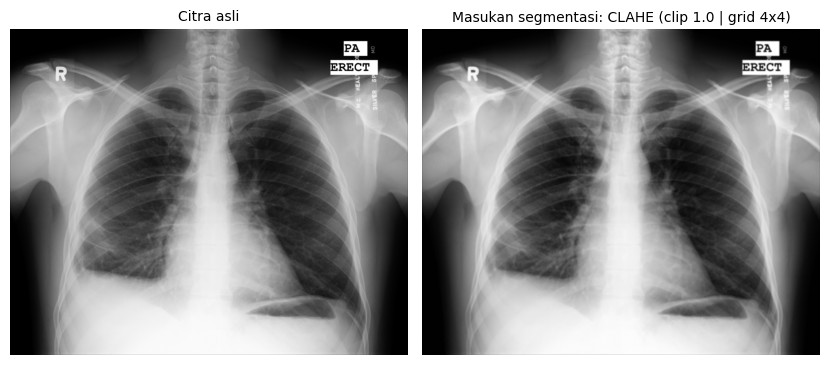

In [12]:
# ===================== PERSIAPAN SEGMENTASI =====================
# Citra masukan = citra hasil peningkatan terbaik, di-smoothing ringan untuk menekan noise.
# Target segmentasi: lapang paru kiri & kanan. Seluruh visualisasi dibuat dengan OpenCV
# (cv2.drawContours, cv2.addWeighted, cv2.circle, cv2.applyColorMap); matplotlib hanya dipakai untuk menampilkan.
seg_img = cv2.GaussianBlur(best_img, (5, 5), 0)
seg_bgr = cv2.cvtColor(seg_img, cv2.COLOR_GRAY2BGR)
SEG = {}          # hasil mask tiap metode

def clean_lung_mask(mask, n_keep=2, min_area_ratio=0.01):
    # Pasca-proses: buka-tutup morfologi, pilih n_keep komponen terbesar yang pusatnya berada di area toraks
    # (membuang latar gelap di luar tubuh), isi lubang, lalu haluskan.
    m = (mask > 0).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    n, lab, stats, cent = cv2.connectedComponentsWithStats(m, connectivity=8)
    cands = []
    for i in range(1, n):
        cx, cy = cent[i]
        if stats[i, cv2.CC_STAT_AREA] >= min_area_ratio * H * W and 0.15 * W < cx < 0.85 * W and 0.15 * H < cy < 0.90 * H:
            cands.append((stats[i, cv2.CC_STAT_AREA], i))
    out = np.zeros_like(m)
    for _, i in sorted(cands, reverse=True)[:n_keep]:
        out[lab == i] = 1
    out = ndi.binary_fill_holes(out).astype(np.uint8)
    out = cv2.morphologyEx(out, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    return out * 255

def draw_overlay(gray, mask, color=(0, 255, 0), alpha=0.35):
    bgr = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR) if gray.ndim == 2 else gray.copy()
    fill = bgr.copy(); fill[mask > 0] = color
    out = cv2.addWeighted(fill, alpha, bgr, 1 - alpha, 0)
    cnts, _ = cv2.findContours((mask > 0).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, cnts, -1, color, 2)
    return out

def find_lung_seeds(gray):
    # Seed otomatis: titik tergelap (pada citra yang sangat di-blur) di sekitar posisi umum paru kanan & kiri
    blur = cv2.GaussianBlur(gray, (0, 0), 25)
    seeds = []
    for fx in (0.30, 0.70):
        x0, x1 = int((fx - 0.10) * W), int((fx + 0.10) * W)
        y0, y1 = int(0.30 * H), int(0.60 * H)
        sub = blur[y0:y1, x0:x1]
        dy, dx = np.unravel_index(np.argmin(sub), sub.shape)
        seeds.append((x0 + dx, y0 + dy))
    return seeds

def area_pct(mask): return 100.0 * (mask > 0).sum() / mask.size
print("Persiapan selesai. Citra masukan segmentasi:", BEST_KEY)
show_grid([("Citra asli", img), (f"Masukan segmentasi: {BEST_KEY[0]} ({BEST_KEY[1]})", seg_img)], ncols=2)

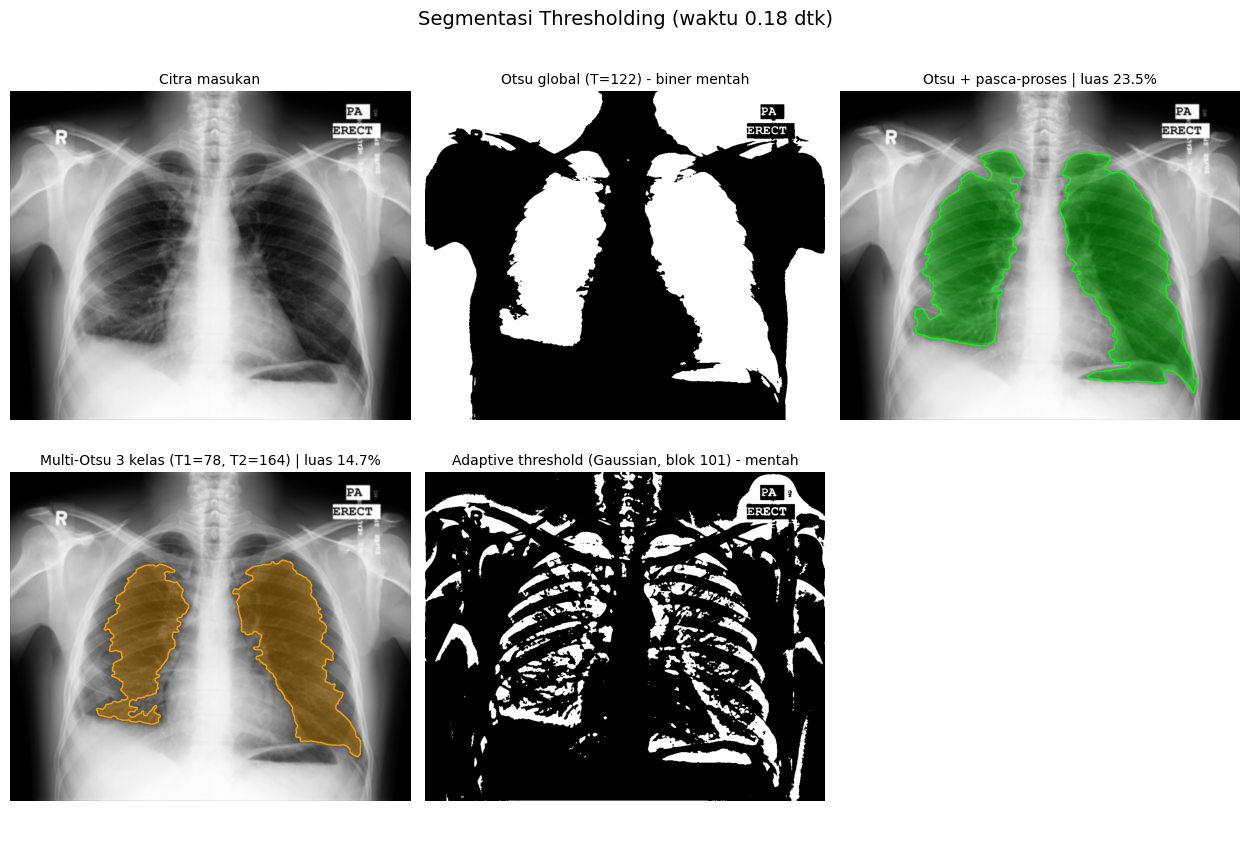

In [13]:
# ===================== 1) THRESHOLDING =====================
t0 = time.time()
otsu_t, otsu_bin = cv2.threshold(seg_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)   # piksel gelap = putih
otsu_mask = clean_lung_mask(otsu_bin)

mt = filters.threshold_multiotsu(seg_img, classes=3)
multi_bin = ((seg_img <= mt[0]) * 255).astype(np.uint8)
multi_mask = clean_lung_mask(multi_bin)

adapt_bin = cv2.adaptiveThreshold(seg_img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 101, 8)
dt = time.time() - t0

SEG["Thresholding"] = otsu_mask
show_grid([
    ("Citra masukan", seg_img),
    (f"Otsu global (T={otsu_t:.0f}) - biner mentah", otsu_bin),
    (f"Otsu + pasca-proses | luas {area_pct(otsu_mask):.1f}%", draw_overlay(seg_img, otsu_mask)),
    (f"Multi-Otsu 3 kelas (T1={mt[0]}, T2={mt[1]}) | luas {area_pct(multi_mask):.1f}%", draw_overlay(seg_img, multi_mask, (0, 165, 255))),
    ("Adaptive threshold (Gaussian, blok 101) - mentah", adapt_bin),
], ncols=3, title=f"Segmentasi Thresholding (waktu {dt:.2f} dtk)")

### Thresholding: kelebihan dan keterbatasan

> Catatan: sesuaikan dengan hasil visual pada eksekusi di Kaggle.

**Kelebihan**
- Sangat sederhana dan cepat (satu operasi per piksel); Otsu menentukan ambang otomatis tanpa parameter manual.
- Paru berisi udara sehingga lebih gelap daripada jaringan sekitar, sehingga intensitas saja sudah cukup memberi kandidat lapang paru yang masuk akal.
- Multi-Otsu memberi pemisahan lebih halus (udara/paru, jaringan lunak, tulang) dibanding satu ambang.

**Keterbatasan**
- Hanya memakai intensitas dan mengabaikan informasi spasial: latar gelap di luar tubuh, gas lambung, dan area gelap lain ikut terdeteksi, sehingga butuh pasca-proses (komponen terhubung, morfologi).
- Intensitas paru tidak homogen (gradasi atas-bawah, bayangan jantung, pembuluh, lesi TB yang lebih terang) sehingga ambang global dapat membuat lubang atau bagian paru yang tidak terambil. Lesi TB yang terang berisiko dianggap bukan paru.
- Adaptive threshold bereaksi pada perubahan lokal sehingga lebih cocok untuk mendeteksi tepi/tekstur daripada area homogen seperti lapang paru.
- Hasil sensitif terhadap metode peningkatan citra yang dipakai sebelumnya.

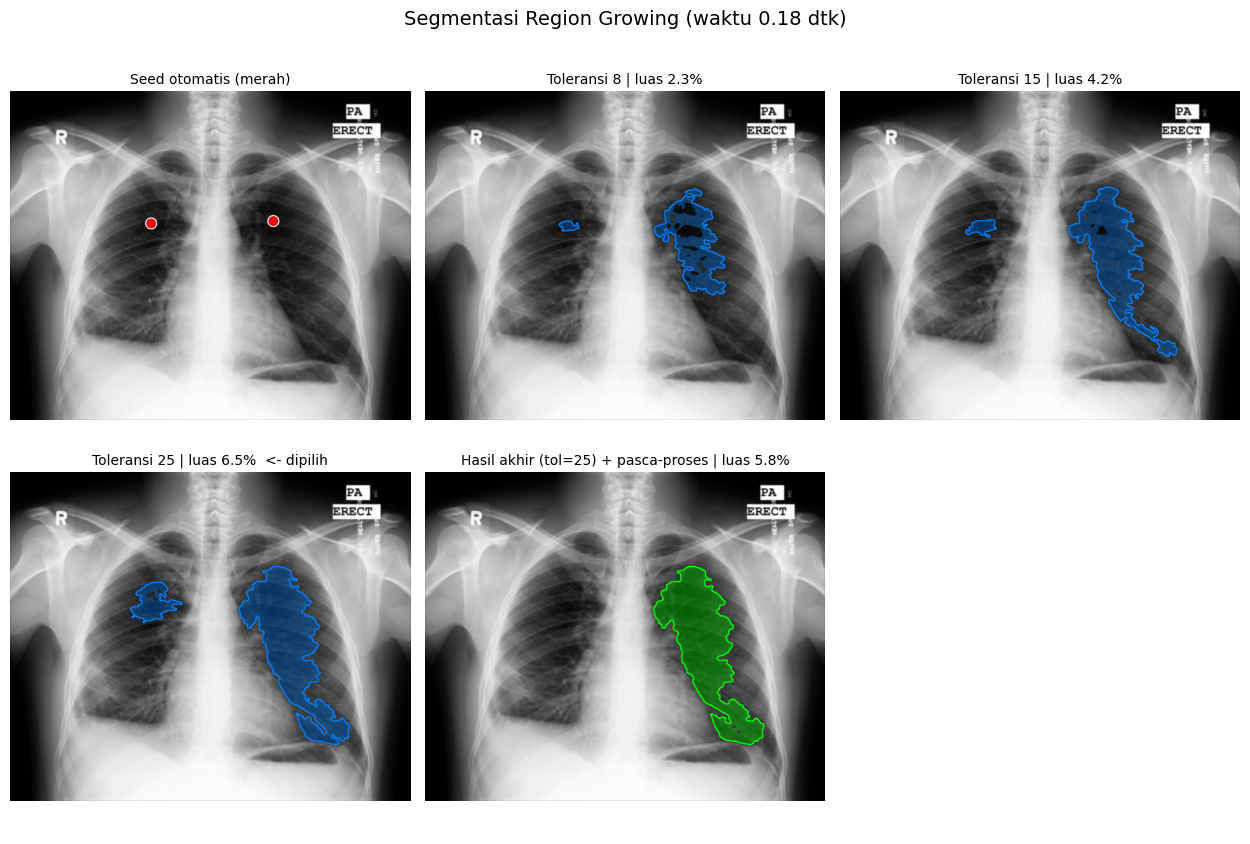

In [14]:
# ===================== 2) REGION GROWING =====================
# Seed otomatis di paru kiri & kanan; piksel tetangga (4-konektivitas) digabung jika |I(p) - I(seed)| <= toleransi.
# Diimplementasikan dengan cv2.floodFill (mode FIXED_RANGE) pada citra yang sudah di-median-blur.
t0 = time.time()
src = cv2.medianBlur(seg_img, 7)
seeds = find_lung_seeds(seg_img)

def grow(tol):
    msk = np.zeros((H + 2, W + 2), np.uint8)
    flags = 4 | cv2.FLOODFILL_FIXED_RANGE | cv2.FLOODFILL_MASK_ONLY | (255 << 8)
    for sx, sy in seeds:
        cv2.floodFill(src, msk, (sx, sy), 0, (tol,) * 3, (tol,) * 3, flags)
    return msk[1:-1, 1:-1]

tols = [8, 15, 25]
raw_grown = {t: grow(t) for t in tols}

# toleransi otomatis: yang terbesar yang luasnya masih wajar untuk paru (<= 45% citra, tidak "bocor")
chosen = tols[0]
for t in tols:
    if area_pct(raw_grown[t]) <= 45: chosen = t
rg_mask = clean_lung_mask(raw_grown[chosen])
SEG["Region Growing"] = rg_mask
dt = time.time() - t0

seed_vis = seg_bgr.copy()
for sx, sy in seeds:
    cv2.circle(seed_vis, (sx, sy), 12, (0, 0, 255), -1); cv2.circle(seed_vis, (sx, sy), 14, (255, 255, 255), 2)

items = [("Seed otomatis (merah)", seed_vis)]
for t in tols:
    items.append((f"Toleransi {t} | luas {area_pct(raw_grown[t]):.1f}%" + ("  <- dipilih" if t == chosen else ""),
                  draw_overlay(seg_img, raw_grown[t], (255, 128, 0))))
items.append((f"Hasil akhir (tol={chosen}) + pasca-proses | luas {area_pct(rg_mask):.1f}%", draw_overlay(seg_img, rg_mask)))
show_grid(items, ncols=3, title=f"Segmentasi Region Growing (waktu {dt:.2f} dtk)")

### Region Growing: kelebihan dan keterbatasan

> Catatan: sesuaikan dengan hasil visual pada eksekusi di Kaggle.

**Kelebihan**
- Menghasilkan wilayah yang terhubung secara spasial dan batasnya mengikuti kemiripan intensitas, sehingga tidak memunculkan piksel acak seperti thresholding.
- Intuitif dan mudah dikendalikan lewat seed dan toleransi; membuat paru kiri dan kanan dapat disegmentasi terpisah.
- Tampak pada percobaan toleransi: toleransi kecil menghasilkan wilayah konservatif, toleransi besar memperluas wilayah.

**Keterbatasan**
- Sangat bergantung pada posisi seed dan nilai toleransi; seed yang jatuh pada pembuluh, iga, atau lesi dapat menghasilkan wilayah yang salah.
- Toleransi terlalu besar menyebabkan kebocoran (region menyebar ke luar paru lewat area gelap yang bersambung, mis. gas lambung atau latar), toleransi terlalu kecil menyebabkan under-segmentation karena gradasi intensitas paru.
- Tepi paru yang kontrasnya rendah (sudut kostofrenikus, apeks, area di balik jantung) tidak terambil dengan baik.
- Seed pada penelitian ini otomatis berdasarkan posisi umum paru, sehingga tidak berlaku pada citra dengan posisi pasien yang sangat berbeda.

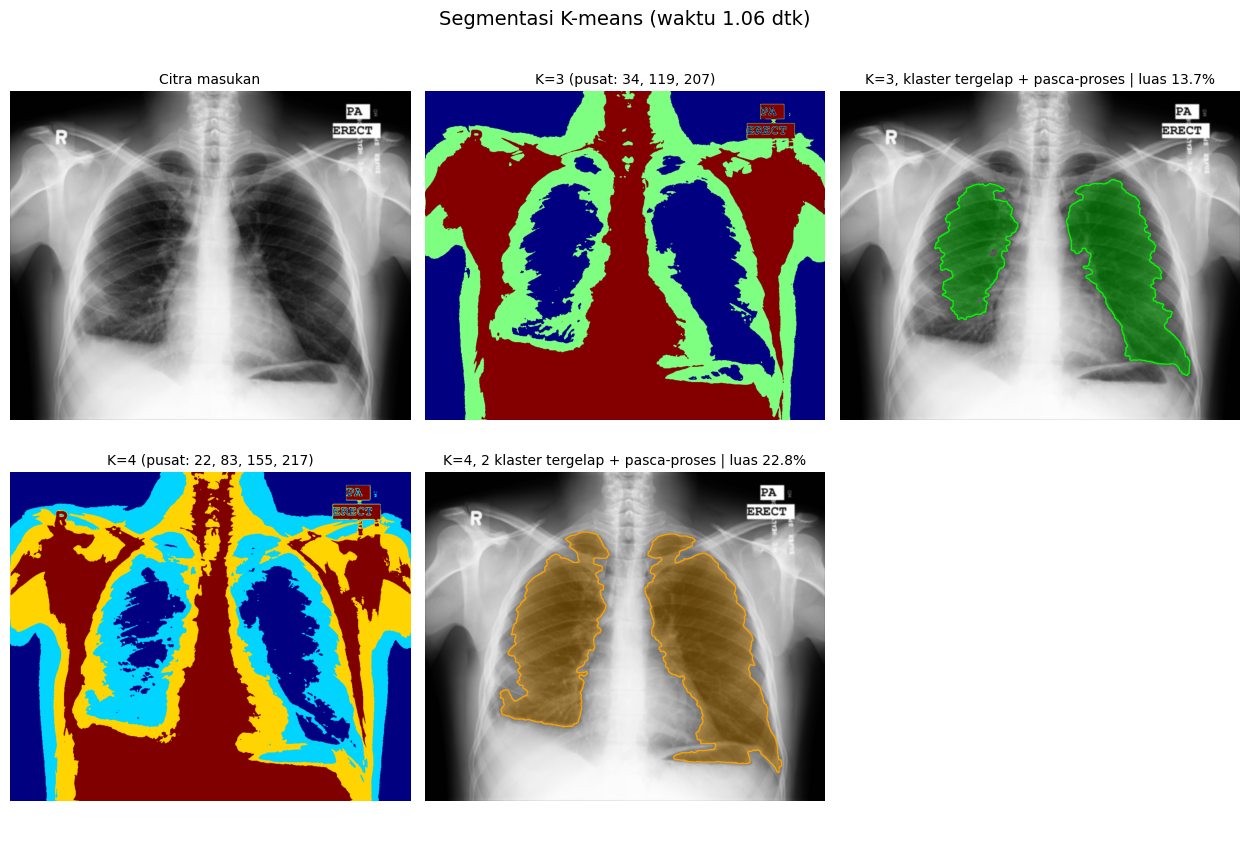

In [15]:
# ===================== 3) CLUSTERING: K-MEANS (cv2.kmeans pada intensitas piksel) =====================
def kmeans_intensity(gray, K):
    cv2.setRNGSeed(0)
    data = gray.reshape(-1, 1).astype(np.float32)
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.5)
    _, labels, centers = cv2.kmeans(data, K, None, crit, 3, cv2.KMEANS_PP_CENTERS)
    order = np.argsort(centers.ravel()); rank = np.empty(K, int); rank[order] = np.arange(K)
    return rank[labels.ravel()].reshape(gray.shape).astype(np.uint8), np.sort(centers.ravel())   # 0 = klaster tergelap

def label_color(lab, K): return cv2.applyColorMap((lab * (255 // (K - 1))).astype(np.uint8), cv2.COLORMAP_JET)

t0 = time.time()
lab3, c3 = kmeans_intensity(seg_img, 3)
lab4, c4 = kmeans_intensity(seg_img, 4)
km3_mask = clean_lung_mask(lab3 == 0)
km4_mask = clean_lung_mask(lab4 <= 1)
SEG["K-means"] = km3_mask
dt = time.time() - t0

show_grid([
    ("Citra masukan", seg_img),
    (f"K=3 (pusat: {', '.join(f'{c:.0f}' for c in c3)})", label_color(lab3, 3)),
    (f"K=3, klaster tergelap + pasca-proses | luas {area_pct(km3_mask):.1f}%", draw_overlay(seg_img, km3_mask)),
    (f"K=4 (pusat: {', '.join(f'{c:.0f}' for c in c4)})", label_color(lab4, 4)),
    (f"K=4, 2 klaster tergelap + pasca-proses | luas {area_pct(km4_mask):.1f}%", draw_overlay(seg_img, km4_mask, (0, 165, 255))),
], ncols=3, title=f"Segmentasi K-means (waktu {dt:.2f} dtk)")

### K-means: kelebihan dan keterbatasan

> Catatan: sesuaikan dengan hasil visual pada eksekusi di Kaggle.

**Kelebihan**
- Tanpa seed dan tanpa pelatihan; pusat klaster ditentukan otomatis dari distribusi intensitas.
- Memberi pembagian citra ke beberapa kelas jaringan (udara/paru, jaringan lunak, tulang/padat) sekaligus, sehingga lebih informatif daripada satu ambang biner.
- Cukup cepat dan mudah diinterpretasi lewat peta klaster berwarna.

**Keterbatasan**
- Jumlah klaster K harus ditentukan manual dan sangat memengaruhi hasil; K=3 dan K=4 pada percobaan memberi pembagian yang berbeda.
- Hanya memakai intensitas (tanpa informasi spasial), sehingga piksel yang jauh letaknya tetapi sama gelapnya (paru, latar luar, gas lambung) masuk klaster yang sama dan perlu pasca-proses.
- Mengasumsikan klaster berbentuk bulat dan berukuran mirip, sedangkan distribusi intensitas citra X-ray tidak simetris; hasil juga dapat berubah mengikuti inisialisasi.
- Rawan terhadap noise dan ketidakhomogenan intensitas, serta menghasilkan batas yang bergerigi tanpa pasca-proses.

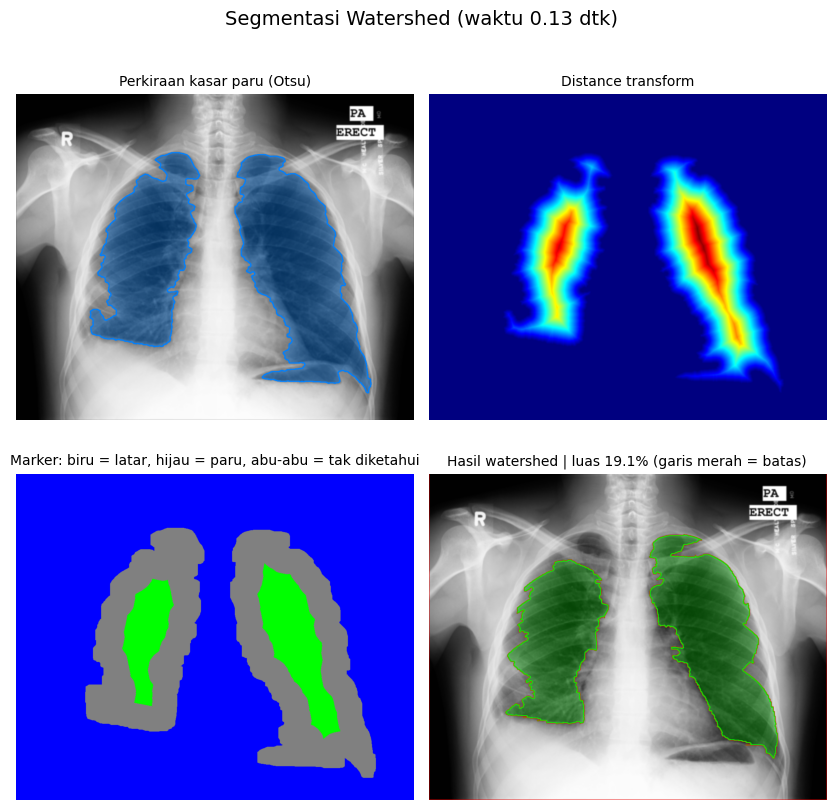

In [16]:
# ===================== 4) WATERSHED (marker-controlled, cv2.watershed) =====================
t0 = time.time()
_, ot_bin = cv2.threshold(seg_img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
coarse = clean_lung_mask(ot_bin)                                    # perkiraan kasar paru (dipakai untuk membuat marker)

dist = cv2.distanceTransform((coarse > 0).astype(np.uint8), cv2.DIST_L2, 5)
sure_fg = (dist > 0.45 * dist.max()).astype(np.uint8)                # inti paru
sure_bg = cv2.dilate(coarse, np.ones((3, 3), np.uint8), iterations=12) == 0   # jauh dari paru = latar

n_lab, fg_lab = cv2.connectedComponents(sure_fg)
markers = np.zeros((H, W), np.int32)
markers[sure_bg] = 1                                                 # 1 = latar
markers[fg_lab > 0] = fg_lab[fg_lab > 0] + 1                        # 2.. = paru (tiap komponen satu label)
marker_vis = np.full((H, W, 3), 128, np.uint8)
marker_vis[markers == 1] = (255, 0, 0); marker_vis[markers > 1] = (0, 255, 0)

ws = cv2.watershed(seg_bgr, markers.copy())
ws_mask = ndi.binary_fill_holes(ws > 1).astype(np.uint8) * 255
SEG["Watershed"] = ws_mask
dt = time.time() - t0

ws_vis = draw_overlay(seg_img, ws_mask, (0, 255, 0), 0.25)
ws_vis[ws == -1] = (0, 0, 255)                                       # garis watershed (merah)
dist_vis = cv2.applyColorMap(cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), cv2.COLORMAP_JET)

show_grid([
    ("Perkiraan kasar paru (Otsu)", draw_overlay(seg_img, coarse, (255, 128, 0))),
    ("Distance transform", dist_vis),
    ("Marker: biru = latar, hijau = paru, abu-abu = tak diketahui", marker_vis),
    (f"Hasil watershed | luas {area_pct(ws_mask):.1f}% (garis merah = batas)", ws_vis),
], ncols=2, title=f"Segmentasi Watershed (waktu {dt:.2f} dtk)")

### Watershed: kelebihan dan keterbatasan

> Catatan: sesuaikan dengan hasil visual pada eksekusi di Kaggle.

**Kelebihan**
- Menghasilkan kontur tertutup yang mengikuti tepi/gradien citra, sehingga batas paru umumnya lebih rapi daripada thresholding murni.
- Dengan marker, region tumbuh dari area yang pasti paru dan pasti latar lalu bertemu pada punggung gradien, sehingga cocok memisahkan objek yang bersentuhan.
- Tiap komponen marker menghasilkan label sendiri sehingga paru kiri dan kanan terpisah secara alami.

**Keterbatasan**
- Tanpa marker, watershed mengalami over-segmentation parah karena noise dan tekstur; kualitas hasil sangat bergantung pada marker.
- Pada percobaan ini marker diturunkan dari Otsu sehingga kesalahan tahap awal (mis. paru yang tidak terdeteksi atau area gelap non-paru) terbawa ke hasil akhir.
- Tepi iga, pembuluh, dan batas jantung menghasilkan banyak gradien kuat yang dapat menghentikan banjir lebih awal atau membelokkan garis batas.
- Pemilihan ambang distance transform dan ukuran dilasi latar adalah parameter manual.

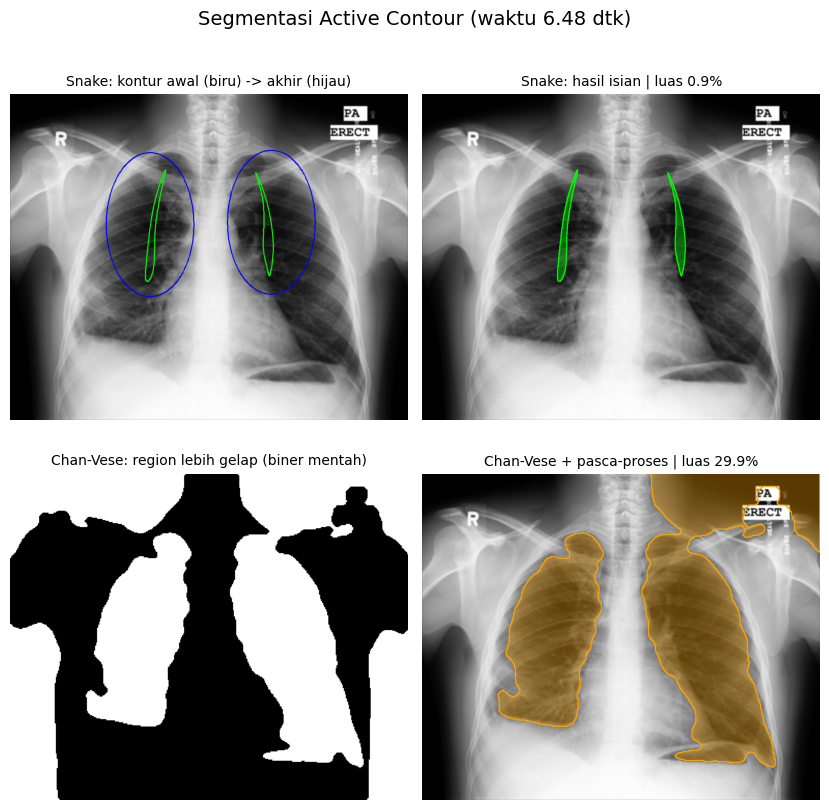

In [17]:
# ===================== 5) ACTIVE CONTOUR =====================
# (a) Snake (skimage.segmentation.active_contour): kontur parametrik dari elips awal di sekitar tiap paru.
# (b) Chan-Vese (morphological_chan_vese): active contour berbasis region (level set), tanpa bergantung pada tepi.
# Dikerjakan pada citra diperkecil (lebar 384) agar cepat, lalu hasil dikembalikan ke ukuran asli.
t0 = time.time()
sw = 384; s = sw / W; sh = int(round(H * s))
small = cv2.resize(seg_img, (sw, sh), interpolation=cv2.INTER_AREA)
small_f = cv2.GaussianBlur(small, (0, 0), 3).astype(np.float64) / 255.0

def ellipse_init(cx, cy, rx, ry, n=240):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return np.stack([cy + ry * np.sin(t), cx + rx * np.cos(t)], axis=1)       # urutan (row, col)

seeds_s = [(sx * s, sy * s) for sx, sy in find_lung_seeds(seg_img)]
inits = [ellipse_init(cx, cy, 0.11 * sw, 0.22 * sh) for cx, cy in seeds_s]
snakes = [segmentation.active_contour(small_f, ini, alpha=0.015, beta=10, gamma=0.001, w_line=-0.3, w_edge=1.0, max_num_iter=500)
          for ini in inits]

def to_full_poly(pts):    # (row, col) skala kecil -> (x, y) skala penuh
    return np.round(np.stack([pts[:, 1], pts[:, 0]], axis=1) / s).astype(np.int32)

snake_vis = seg_bgr.copy(); snake_mask = np.zeros((H, W), np.uint8)
for ini, sn in zip(inits, snakes):
    cv2.polylines(snake_vis, [to_full_poly(ini)], True, (255, 0, 0), 2)          # awal = biru
    cv2.polylines(snake_vis, [to_full_poly(sn)], True, (0, 255, 0), 2)           # akhir = hijau
    cv2.fillPoly(snake_mask, [to_full_poly(sn)], 255)

cv_small = segmentation.morphological_chan_vese(small_f, num_iter=200, init_level_set="checkerboard", smoothing=2).astype(bool)
dark_is_one = small_f[cv_small].mean() < small_f[~cv_small].mean()
cv_dark = cv_small if dark_is_one else ~cv_small                                 # region yang lebih gelap = kandidat paru
cv_full = cv2.resize(cv_dark.astype(np.uint8) * 255, (W, H), interpolation=cv2.INTER_NEAREST)
cv_mask = clean_lung_mask(cv_full)
SEG["Active Contour"] = snake_mask
dt = time.time() - t0

show_grid([
    ("Snake: kontur awal (biru) -> akhir (hijau)", snake_vis),
    (f"Snake: hasil isian | luas {area_pct(snake_mask):.1f}%", draw_overlay(seg_img, snake_mask)),
    ("Chan-Vese: region lebih gelap (biner mentah)", cv_full),
    (f"Chan-Vese + pasca-proses | luas {area_pct(cv_mask):.1f}%", draw_overlay(seg_img, cv_mask, (0, 165, 255))),
], ncols=2, title=f"Segmentasi Active Contour (waktu {dt:.2f} dtk)")

### Active Contour: kelebihan dan keterbatasan

> Catatan: sesuaikan dengan hasil visual pada eksekusi di Kaggle.

**Kelebihan**
- Menghasilkan kontur tertutup yang mulus dan kontinu (resolusi sub-piksel pada snake), dengan regularisasi (alpha, beta) yang membuat batas tidak bergerigi.
- Snake mengikuti tepi anatomi sehingga bagus untuk menyempurnakan batas organ ketika inisialisasi sudah dekat.
- Chan-Vese tidak membutuhkan tepi yang tajam dan relatif tahan terhadap noise, serta mampu menangani perubahan topologi (satu atau dua paru, lubang).

**Keterbatasan**
- Snake sangat bergantung pada inisialisasi (elips awal harus dekat dengan batas paru) dan pada parameter (alpha, beta, gamma, bobot garis/tepi); parameter yang kurang tepat membuat kontur menciut, menempel pada tepi iga atau pembuluh, atau terjebak pada minimum lokal.
- Kurang mampu mengikuti batas paru yang cekung/tidak beraturan (sudut kostofrenikus, area di balik jantung) dan paru pada citra TB dengan lesi atau pleura yang tidak jelas.
- Chan-Vese hanya mengasumsikan dua region dengan intensitas rata-rata homogen sehingga hasilnya cenderung memecah citra berdasarkan gradasi pencahayaan global, bukan paru secara spesifik, dan masih memerlukan pasca-proses.
- Iteratif sehingga lebih lambat daripada metode lain, dan seperti metode lain hasilnya tidak dievaluasi terhadap ground-truth mask pada notebook ini.

## Kesimpulan

**Peningkatan citra.** Tiga metode (Histogram Equalization, CLAHE, Gamma Correction) dibandingkan secara kuantitatif memakai entropy, kontras, EME, ketajaman, AMBE, PSNR, dan SSIM, lalu dirangkum dalam skor gabungan. Hasil metode terbaik dan parameternya dilaporkan pada sel analisis otomatis di atas (bagian "Analisis Hasil Peningkatan Citra"). Secara umum, Global HE dan AHE menaikkan kontras paling besar namun paling banyak mengubah brightness dan menguatkan noise; Gamma menjaga struktur tetapi tidak menambah kontras lokal; CLAHE dengan clip limit dan grid size yang moderat memberi kompromi terbaik antara peningkatan kontras lokal dan kesetiaan terhadap citra asli, sehingga paling sesuai untuk menonjolkan struktur paru pada citra TB.

**Segmentasi.** Lima metode klasik (Thresholding, Region Growing, K-means, Watershed, Active Contour) menghasilkan segmentasi lapang paru dengan karakter berbeda: Thresholding dan K-means cepat dan tanpa seed tetapi hanya memakai intensitas sehingga membutuhkan pasca-proses; Region Growing menjaga konektivitas tetapi sensitif terhadap seed dan toleransi; Watershed memberi batas yang mengikuti gradien tetapi bergantung pada kualitas marker; Active Contour memberi kontur halus tetapi sangat bergantung pada inisialisasi dan parameter. Semua metode lebih baik bila masukannya sudah ditingkatkan kontrasnya, dan tidak ada satu metode yang sempurna untuk seluruh bagian paru.

**Keterbatasan dan saran.** Eksperimen dilakukan pada satu citra (MCUCXR_0182_1) sehingga kesimpulan belum dapat digeneralisasi. Metrik peningkatan citra bersifat tanpa referensi dan tidak menggantikan penilaian klinis, sedangkan segmentasi dinilai secara visual tanpa metrik overlap. Pengembangan berikutnya: evaluasi pada banyak citra Montgomery/Shenzhen, hitung Dice/IoU/Jaccard terhadap mask ground-truth (tersedia pada dataset Montgomery), kombinasikan beberapa metode (mis. Otsu + Watershed + Active Contour), dan bandingkan dengan pendekatan deep learning seperti U-Net.